In [1]:
import os
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from astropy.coordinates import SkyCoord
import astropy.units as u

from astrodendro import Dendrogram
from photutils.segmentation import SegmentationImage, deblend_sources
from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

from skimage import measure
from skimage.measure import regionprops
from skimage.segmentation import find_boundaries
from skimage.measure import regionprops_table

from tqdm.notebook import tqdm

from pathlib import Path
import json

In [2]:
def percentile_norm(img, pmin=1, pmax=99):
    x = np.array(img, dtype=float, copy=True)
    x[~np.isfinite(x)] = np.nan

    lo, hi = np.nanpercentile(x, [pmin, pmax])
    x = (x - lo) / (hi - lo)
    x = np.clip(x, 0, 1)
    return x 

In [3]:
def clean_map(x):
    y = np.array(x, dtype=float, copy=True)
    y[~np.isfinite(y)] = 0.0
    y[y < 0] = 0.0
    return y

In [4]:
def mask_pn_cat(cat, wcs, shape, radius_factor=2.0):
    mask = np.zeros(shape, dtype=bool)

    coords = SkyCoord(cat["RAdeg"].values * u.deg, cat["DEdeg"].values * u.deg)
    x, y = wcs.world_to_pixel(coords)

    yy, xx = np.indices(shape)

    for xi, yi, fwhm_arcsec in zip(x, y, cat["FWHM"].values):
        if not np.isfinite(xi) or not np.isfinite(yi):
            continue

        r_pix = radius_factor * fwhm_arcsec / pix_scale
        source_mask = (xx - xi)**2 + (yy - yi)**2 <= r_pix**2
        mask |= source_mask

    return mask

In [5]:
'''
def det_map(ha, ha_err, oiii, oiii_err, sii, sii_err, snr_min):

    fluxes = [ha, oiii, sii]
    errors = [ha_err, oiii_err, sii_err]

    detection_sq = np.zeros_like(ha, dtype=float)

    for flux, err in zip(fluxes, errors):
        flux = np.asarray(flux, dtype=float)
        err = np.asarray(err, dtype=float)

        valid = np.isfinite(flux) & np.isfinite(err) & (err > 0)

        snr = np.zeros_like(flux, dtype=float)
        snr[valid] = flux[valid] / err[valid]

        snr = np.where(snr > snr_min, snr, 0.0)

        detection_sq += snr**2

    detection = np.sqrt(detection_sq)
    detection[~np.isfinite(detection)] = 0.0

    return detection
'''

def global_noise(err, method="median"):
    err = np.asarray(err, dtype=float)

    valid = np.isfinite(err) & (err > 0)
    vals = err[valid]

    if method == "median":
        return np.nanmedian(vals)

    elif method == "rms":
        return np.sqrt(np.nanmedian(vals**2))

    elif method == "percentile":
        return np.nanpercentile(vals, 60)

    else:
        return np.nanmean(vals)


def det_map(ha, ha_err, oiii, oiii_err, sii, sii_err, snr_min=0.0, noise_method="median"):

    fluxes = [ha, oiii, sii]
    errors = [ha_err, oiii_err, sii_err]

    noises = [global_noise(err, method=noise_method) for err in errors]

    detection_sq = np.zeros_like(ha, dtype=float)

    for flux, noise in zip(fluxes, noises):
        flux = np.asarray(flux, dtype=float)

        valid = np.isfinite(flux)

        snr = np.zeros_like(flux, dtype=float)
        snr[valid] = flux[valid] / noise

        snr = np.clip(snr, 0, None)

        if snr_min > 0:
            snr = np.where(snr > snr_min, snr, 0.0)

        detection_sq += snr**2

    detection = np.sqrt(detection_sq)
    detection[~np.isfinite(detection)] = 0.0

    return detection

In [6]:
def get_label_array(label_obj):
    if isinstance(label_obj, np.ndarray):
        arr = label_obj
    elif hasattr(label_obj, "data") and isinstance(label_obj.data, np.ndarray):
        arr = label_obj.data
    else:
        arr = np.asarray(label_obj)

    return arr.astype(np.int32)


def count_regions(label_array):
    return len(np.unique(label_array[label_array > 0]))

In [7]:
def comp_dendro(input_den, value, delta, npix):
    d = Dendrogram.compute(
        input_den,
        min_value=value,
        min_delta=delta,
        min_npix=npix)

    labels_dendro = np.zeros(input_den.shape, dtype=np.int32)
    for i, leaf in enumerate(d.leaves, start=1):
        labels_dendro[leaf.get_mask()] = i

    print(f"Astrodendro leaves count: {len(d.leaves)}")

    show = labels_dendro.astype(float)
    show[show == 0] = np.nan
    return labels_dendro, show

In [8]:
def conv(labels, detection, n_pixels, smooth_sigma,
    smooth_threshold, n_levels, contrast):
    binary_mask = labels > 0

    smooth_mask = ndi.gaussian_filter(binary_mask.astype(float), sigma=smooth_sigma)

    smooth_mask = smooth_mask > smooth_threshold

    connected_labels, n_connected = ndi.label(smooth_mask)

    segm = SegmentationImage(connected_labels.astype(np.int32))
    deblend_data = clean_map(detection)

    labels_final = deblend_sources(deblend_data, segm, n_pixels=n_pixels,
                                   n_levels=n_levels, contrast=contrast)

    print(f"final deblended regions: {labels_final.data.astype(np.int32).max()}")

    show = labels_final.data.astype(np.int32).astype(float)
    show[show == 0] = np.nan

    return labels_final, show

In [9]:
def plot_segmentation_result(run_name, result, detection):
    det_show = percentile_norm(detection)

    dendro_data = result["dendro_data"]
    conv_data = result["labels_data"]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(det_show, origin="lower")
    axes[0].contour(dendro_data > 0, levels=[0.5], linewidths=0.7, colors="red")
    axes[0].set_title(f"{run_name}\ncomp_dendro: {result['n_dendro_regions']} regions")
    axes[0].set_xticks([])
    axes[0].set_yticks([])

    axes[1].imshow(det_show, origin="lower")
    axes[1].contour(conv_data > 0, levels=[0.5], linewidths=0.7, colors="red")
    axes[1].set_title(f"{run_name}\nconv/deblend: {result['n_conv_regions']} regions")
    axes[1].set_xticks([])
    axes[1].set_yticks([])

    plt.tight_layout()
    plt.show()

In [10]:
def safe_ratio(num, den):
    out = np.full_like(num, np.nan, dtype=float)
    mask = np.isfinite(num) & np.isfinite(den) & (den > 0) & (num > 0)
    out[mask] = num[mask] / den[mask]
    return out

In [11]:
def sum_in_mask(arr, mask):
    x = np.asarray(arr, dtype=float)
    return np.nansum(x[mask])

In [12]:
def err_sum_in_mask(err, mask):
    e = np.asarray(err, dtype=float)
    vals = e[mask]
    vals = vals[np.isfinite(vals) & (vals > 0)]
    return np.sqrt(np.nansum(vals**2))

In [13]:
def classify_bpt(log_nii_ha, log_oiii_hb):
    if not (np.isfinite(log_nii_ha) and np.isfinite(log_oiii_hb)):
        return "unclassified_BPT"

    kewley = 0.61 / (log_nii_ha - 0.47) + 1.19
    kauff  = 0.61 / (log_nii_ha - 0.05) + 1.30

    if log_nii_ha < 0.05 and log_oiii_hb < kauff:
        return "HII_BPT_clean"
    elif log_nii_ha < 0.47 and log_oiii_hb < kewley:
        return "HII_BPT_possible"
    else:
        return "non_HII_BPT"

In [14]:
def plot_region_contours(base_image, labels_data, region_ids, title, contour_color="red"):
    fig, ax = plt.subplots(figsize=(10, 5))
    
    ax.imshow(base_image, origin="lower")

    count_drawn = 0

    for rid in region_ids:
        mask = labels_data == rid

        if not np.any(mask):
            continue

        contours = measure.find_contours(mask.astype(float), level=0.5)

        for contour in contours:
            ax.plot(contour[:, 1], contour[:, 0], color=contour_color, linewidth=1.3)

        count_drawn += 1

    ax.set_title(f"{title} ({count_drawn} regions)")
    ax.set_xlabel("x [pix]")
    ax.set_ylabel("y [pix]")
    plt.tight_layout()
    plt.show()

In [15]:
def plot_single_region(image, labels_data, region_id, title_prefix="", contour_color="red", pad=20):
    mask = labels_data == region_id

    yy, xx = np.where(mask)
    y0, y1 = yy.min(), yy.max()
    x0, x1 = xx.min(), xx.max()

    y0p = max(0, y0 - pad)
    y1p = min(labels_data.shape[0], y1 + pad + 1)
    x0p = max(0, x0 - pad)
    x1p = min(labels_data.shape[1], x1 + pad + 1)

    img_cut = image[y0p:y1p, x0p:x1p]
    mask_cut = mask[y0p:y1p, x0p:x1p]

    plt.figure(figsize=(6, 6))
    plt.imshow(img_cut, origin="lower")
    plt.colorbar()
    plt.contour(mask_cut.astype(float), levels=[0.5], colors=contour_color, linewidths=1.5)
    plt.title(f"{title_prefix} Region {region_id}")
    plt.show()

In [16]:
def make_segmentation_qa(labels_data, detection,
    ha, ha_err, oiii, oiii_err, sii, sii_err,
    wcs, pix_scale, pn_mask=None,
    compute_det_quantiles=True):
    labels = np.asarray(labels_data, dtype=np.int32)
    detection = np.asarray(detection, dtype=float)

    ny, nx = labels.shape
    max_label = int(labels.max())

    if max_label == 0:
        return pd.DataFrame()


    props = regionprops_table(
        labels,
        properties=(
            "label",
            "centroid",
            "bbox",
            "axis_major_length",
            "axis_minor_length",
            "eccentricity"))

    df = pd.DataFrame(props)
    labs = df["label"].to_numpy(dtype=np.int32)

    # skimage naming:
    # centroid-0 = y, centroid-1 = x
    ycen = df["centroid-0"].to_numpy(float)
    xcen = df["centroid-1"].to_numpy(float)

    minr = df["bbox-0"].to_numpy(int)
    minc = df["bbox-1"].to_numpy(int)
    maxr = df["bbox-2"].to_numpy(int)
    maxc = df["bbox-3"].to_numpy(int)

    # Vectorized WCS conversion
    ra, dec = wcs.wcs_pix2world(xcen, ycen, 0)

    # -----------------------------
    # 2. Fast grouped sums
    # -----------------------------
    flat_labels = labels.ravel()
    minlength = max_label + 1

    npix_all = np.bincount(flat_labels, minlength=minlength)

    def clean_flux(arr):
        arr = np.asarray(arr, dtype=float)
        return np.where(np.isfinite(arr), arr, 0.0)

    def clean_err2(err):
        err = np.asarray(err, dtype=float)
        return np.where(np.isfinite(err) & (err > 0), err * err, 0.0)

    def sum_by_label(arr):
        arr_clean = clean_flux(arr)
        return np.bincount(
            flat_labels,
            weights=arr_clean.ravel(),
            minlength=minlength)

    def err_by_label(err):
        err2 = clean_err2(err)
        return np.sqrt(
            np.bincount(
                flat_labels,
                weights=err2.ravel(),
                minlength=minlength))

    F_ha_all = sum_by_label(ha)
    F_oiii_all = sum_by_label(oiii)
    F_sii_all = sum_by_label(sii)

    E_ha_all = err_by_label(ha_err)
    E_oiii_all = err_by_label(oiii_err)
    E_sii_all = err_by_label(sii_err)

    # -----------------------------
    # 3. Detection peak, median, p90
    # -----------------------------
    # Peak can be computed fast with scipy.ndimage.maximum
    det_for_max = detection.copy()
    det_for_max[~np.isfinite(det_for_max)] = -np.inf

    all_ids = np.arange(1, max_label + 1)
    det_peak_tmp = ndi.maximum(det_for_max, labels, index=all_ids)

    det_peak_all = np.full(minlength, np.nan, dtype=float)
    det_peak_all[all_ids] = det_peak_tmp
    det_peak_all[~np.isfinite(det_peak_all)] = np.nan

    # Median and p90 are harder to fully vectorize.
    # But this loop only uses each region's bounding box, not the full image.
    det_median_all = np.full(minlength, np.nan, dtype=float)
    det_p90_all = np.full(minlength, np.nan, dtype=float)

    if compute_det_quantiles:
        objects = ndi.find_objects(labels)

        for lab, slc in enumerate(objects, start=1):
            if slc is None:
                continue

            local_mask = labels[slc] == lab
            vals = detection[slc][local_mask]
            vals = vals[np.isfinite(vals)]

            if vals.size == 0:
                continue

            det_median_all[lab] = np.nanmedian(vals)
            det_p90_all[lab] = np.nanpercentile(vals, 90)

    # -----------------------------
    # 4. PN overlap
    # -----------------------------
    if pn_mask is not None:
        pn_mask_bool = np.asarray(pn_mask, dtype=bool)
        pn_overlap_all = np.bincount(
            flat_labels,
            weights=pn_mask_bool.ravel().astype(float),
            minlength=minlength,
        )
    else:
        pn_overlap_all = np.zeros(minlength, dtype=float)

    # -----------------------------
    # 5. Build final table
    # -----------------------------
    npix = npix_all[labs].astype(int)
    r_eq_pix = np.sqrt(npix / np.pi)

    major = df["axis_major_length"].to_numpy(float)
    minor = df["axis_minor_length"].to_numpy(float)

    elongation = np.full_like(major, np.nan, dtype=float)
    good_minor = minor > 0
    elongation[good_minor] = major[good_minor] / minor[good_minor]

    F_ha = F_ha_all[labs]
    F_oiii = F_oiii_all[labs]
    F_sii = F_sii_all[labs]

    E_ha = E_ha_all[labs]
    E_oiii = E_oiii_all[labs]
    E_sii = E_sii_all[labs]

    sn_ha = np.divide(F_ha, E_ha, out=np.full_like(F_ha, np.nan), where=E_ha > 0)
    sn_oiii = np.divide(F_oiii, E_oiii, out=np.full_like(F_oiii, np.nan), where=E_oiii > 0)
    sn_sii = np.divide(F_sii, E_sii, out=np.full_like(F_sii, np.nan), where=E_sii > 0)

    pn_overlap_npix = pn_overlap_all[labs].astype(int)
    pn_overlap_frac = np.divide(
        pn_overlap_npix,
        npix,
        out=np.zeros_like(pn_overlap_npix, dtype=float),
        where=npix > 0,
    )

    out = pd.DataFrame({
        "region_id": labs,
        "npix": npix,
        "area_arcsec2": npix * pix_scale**2,
        "r_eq_pix": r_eq_pix,
        "r_eq_arcsec": r_eq_pix * pix_scale,
        "x": xcen,
        "y": ycen,
        "ra": ra,
        "dec": dec,
        "bbox_width": maxc - minc,
        "bbox_height": maxr - minr,
        "edge_touching": (minr == 0) | (minc == 0) | (maxr == ny) | (maxc == nx),
        "major_axis_pix": major,
        "minor_axis_pix": minor,
        "elongation": elongation,
        "eccentricity": df["eccentricity"].to_numpy(float),
        "det_peak": det_peak_all[labs],
        "det_median": det_median_all[labs],
        "det_p90": det_p90_all[labs],
        "F_ha": F_ha,
        "F_oiii": F_oiii,
        "F_sii": F_sii,
        "sn_ha": sn_ha,
        "sn_oiii": sn_oiii,
        "sn_sii": sn_sii,
        "pn_overlap_npix": pn_overlap_npix,
        "pn_overlap_frac": pn_overlap_frac,
    })

    return out

In [17]:
def make_local_annulus(labels_data, region_id, qa_lookup,
    label_slices, inner_factor, outer_factor,
    min_inner_pix=3, min_outer_pix=6, extra_pad=2):
    
    row = qa_lookup.loc[region_id]
    r_eq_pix = row["r_eq_pix"]

    inner_rad = int(np.ceil(max(inner_factor * r_eq_pix, min_inner_pix)))
    outer_rad = int(np.ceil(max(outer_factor * r_eq_pix, min_outer_pix)))

    if outer_rad <= inner_rad:
        outer_rad = inner_rad + 2

    base_slc = label_slices[region_id - 1]

    if base_slc is None:
        return None, None, None

    yslice, xslice = base_slc
    ny, nx = labels_data.shape

    y0 = max(yslice.start - outer_rad - extra_pad, 0)
    y1 = min(yslice.stop  + outer_rad + extra_pad, ny)
    x0 = max(xslice.start - outer_rad - extra_pad, 0)
    x1 = min(xslice.stop  + outer_rad + extra_pad, nx)

    slc = np.s_[y0:y1, x0:x1]
    labels_crop = labels_data[slc]
    src_crop = labels_crop == region_id

    dist = ndi.distance_transform_edt(~src_crop)

    pn_crop = pn_mask[slc]

    ann_crop = ((dist > inner_rad) & (dist <= outer_rad) & (labels_crop == 0) 
                & (~pn_crop))

    return src_crop, ann_crop, slc

In [18]:
def expand_slice(slc, image_shape, pad=40):
    yslc, xslc = slc
    ny, nx = image_shape[:2]

    y0 = max(yslc.start - pad, 0)
    y1 = min(yslc.stop + pad, ny)
    x0 = max(xslc.start - pad, 0)
    x1 = min(xslc.stop + pad, nx)

    return np.s_[y0:y1, x0:x1]

In [19]:
def show_source_annulus(image, source_crop, annulus_crop,
    slc, labels_data=None, title="",
    show_all_regions=True, pad=40,):

    plot_slc = expand_slice(slc, image.shape, pad=pad)

    img_view = image[plot_slc]

    view_shape = img_view.shape[:2]
    src_view = np.zeros(view_shape, dtype=bool)
    ann_view = np.zeros(view_shape, dtype=bool)

    y_offset = slc[0].start - plot_slc[0].start
    x_offset = slc[1].start - plot_slc[1].start

    y_size, x_size = source_crop.shape

    src_view[y_offset:y_offset + y_size,
        x_offset:x_offset + x_size] = source_crop

    ann_view[y_offset:y_offset + y_size,
        x_offset:x_offset + x_size] = annulus_crop

    plt.figure(figsize=(8, 8))
    plt.imshow(img_view, origin="lower")

    if labels_data is not None and show_all_regions:
        lab_view = labels_data[plot_slc]
        all_boundaries = find_boundaries(lab_view, mode="outer")

        plt.contour(all_boundaries.astype(float),
            levels=[0.5], colors="white",
            linewidths=0.5, alpha=0.45)

    if np.any(src_view):
        plt.contour(
            src_view.astype(float),
            levels=[0.5],
            colors="lime",
            linewidths=2.0)

    if np.any(ann_view):
        plt.contour(
            ann_view.astype(float),
            levels=[0.5],
            colors="red",
            linewidths=1.3)

    plt.title(title)
    plt.axis("off")
    plt.show()

In [20]:
def robust_background_stats(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    med = np.nanmedian(values)

    mad = np.nanmedian(np.abs(values - med))
    robust_sigma = 1.4826 * mad

    if not np.isfinite(robust_sigma) or robust_sigma == 0:
        robust_sigma = np.nanstd(values)

    # Approximate standard error of the median
    med_err = 1.253 * robust_sigma / np.sqrt(values.size)

    return med, robust_sigma, med_err, values.size

In [21]:
def extract_region_fluxes(labels_data, region_id, qa_lookup,
    label_slices, line_maps, line_err_maps,
    inner_factor, outer_factor, min_annulus_pix=20):
    
    src_crop, ann_crop, slc = make_local_annulus(labels_data,
        region_id, qa_lookup, label_slices,
        inner_factor=inner_factor, outer_factor=outer_factor)

    if src_crop is None:
        return None

    n_src = int(np.sum(src_crop))
    n_ann = int(np.sum(ann_crop))

    result = {"region_id": region_id, "n_src_pix": n_src,
        "n_ann_pix": n_ann, "flag_bad_annulus": n_ann < min_annulus_pix,}

    for line_name, img in line_maps.items():
        img_crop = img[slc]

        src_vals = img_crop[src_crop]
        ann_vals = img_crop[ann_crop]

        raw_flux = np.nansum(src_vals)

        bg_level, bg_sigma, bg_level_err, n_bg = robust_background_stats(ann_vals)

        bg_flux = bg_level * n_src
        bg_flux_err = bg_level_err * n_src

        corr_flux = raw_flux - bg_flux

        if line_err_maps is not None and line_name in line_err_maps:
            err_crop = line_err_maps[line_name][slc]
            raw_err = np.sqrt(np.nansum(err_crop[src_crop] ** 2))
        else:
            raw_err = np.nan

        corr_err = np.sqrt(raw_err**2 + bg_flux_err**2)

        result[f"{line_name}_raw_flux"] = raw_flux
        result[f"{line_name}_raw_err"] = raw_err
        result[f"{line_name}_raw_sn"] = raw_flux / raw_err if raw_err > 0 else np.nan

        result[f"{line_name}_bg_level"] = bg_level
        result[f"{line_name}_bg_sigma"] = bg_sigma
        result[f"{line_name}_bg_flux"] = bg_flux
        result[f"{line_name}_bg_flux_err"] = bg_flux_err
        result[f"{line_name}_bg_fraction"] = bg_flux / raw_flux if raw_flux != 0 else np.nan

        result[f"{line_name}_corr_flux"] = corr_flux
        result[f"{line_name}_corr_err"] = corr_err
        result[f"{line_name}_corr_sn"] = corr_flux / corr_err if corr_err > 0 else np.nan

    return result

In [22]:
def safe_log10_ratio(num, den):
    num = np.asarray(num, dtype=float)
    den = np.asarray(den, dtype=float)
    out = np.full_like(num, np.nan, dtype=float)
    
    valid = (np.isfinite(num) & np.isfinite(den) & (num > 0) & (den > 0))
    out[valid] = np.log10(num[valid] / den[valid])
    return out

In [23]:
pix_scale = 0.2
psf_fwhm_arcsec = 0.85
psf_fwhm_pix = psf_fwhm_arcsec / pix_scale

In [24]:
path = "/Users/golta/Desktop/Uni/Thesis/Model Selection/Classic_V2.0/ADP.2025-07-06T07_52_11.876.fits"
hdul = fits.open(path, memmap=True)
for i, h in enumerate(hdul):
        print(f"{i:3d}  {h.name:25s}")
        if i==30:
            break

  0  PRIMARY                  
  1  ID                       
  2  FLUX                     
  3  SNR                      
  4  SNRBIN                   
  5  BIN_ID                   
  6  V_STARS                  
  7  FORM_ERR_V_STARS         
  8  SIGMA_STARS              
  9  FORM_ERR_SIGMA_STARS     
 10  H3_STARS                 
 11  FORM_ERR_H3_STARS        
 12  H4_STARS                 
 13  FORM_ERR_H4_STARS        
 14  CHI2_TOT                 
 15  HEII4685_FLUX            
 16  HEII4685_FLUX_ERR        
 17  HEII4685_VEL             
 18  HEII4685_VEL_ERR         
 19  HEII4685_SIGMA           
 20  HEII4685_SIGMA_ERR       
 21  HEII4685_SIGMA_CORR      
 22  HEII4685_MOM0            
 23  HEII4685_MOM0_ERR        
 24  HEII4685_MOM1            
 25  HEII4685_MOM1_ERR        
 26  HEII4685_MOM2            
 27  HEII4685_MOM2_ERR        
 28  HB4861_FLUX              
 29  HB4861_FLUX_ERR          
 30  HB4861_VEL               


In [25]:
ha = hdul["HA6562_FLUX"].data
hb = hdul["HB4861_FLUX"].data
oiii = hdul["OIII5006_FLUX"].data
nii = hdul["NII6583_FLUX"].data
sii6716 = hdul["SII6716_FLUX"].data
sii6730 = hdul["SII6730_FLUX"].data
sii = sii6716 + sii6730
oi = hdul["OI6300_FLUX"].data

oi_err = hdul["OI6300_FLUX_ERR"].data
ha_err = hdul["HA6562_FLUX_ERR"].data
hb_err = hdul["HB4861_FLUX_ERR"].data
oiii_err = hdul["OIII5006_FLUX_ERR"].data
nii_err = hdul["NII6583_FLUX_ERR"].data
sii6716_err = hdul["SII6716_FLUX_ERR"].data
sii6730_err = hdul["SII6730_FLUX_ERR"].data
sii_err = np.sqrt(sii6716_err**2 + sii6730_err**2)

In [26]:
header = hdul["HA6562_FLUX"].header
wcs = WCS(header)

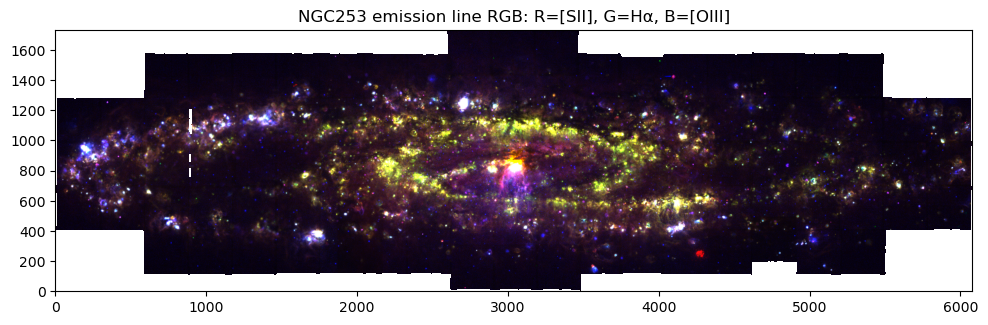

In [27]:
rgb = np.dstack([percentile_norm(sii),percentile_norm(ha),percentile_norm(oiii)])

plt.figure(figsize=(10, 5))
plt.imshow(rgb, origin="lower")
plt.title("NGC253 emission line RGB: R=[SII], G=H\u03B1, B=[OIII]")
plt.tight_layout()
plt.show()

In [28]:
pn_cat = pd.read_csv("/Users/golta/Desktop/Uni/Thesis/Model Selection/Classic_V2.0/PN_CAT.csv")

pn_mask = mask_pn_cat(pn_cat, wcs, ha.shape, radius_factor=2.0)

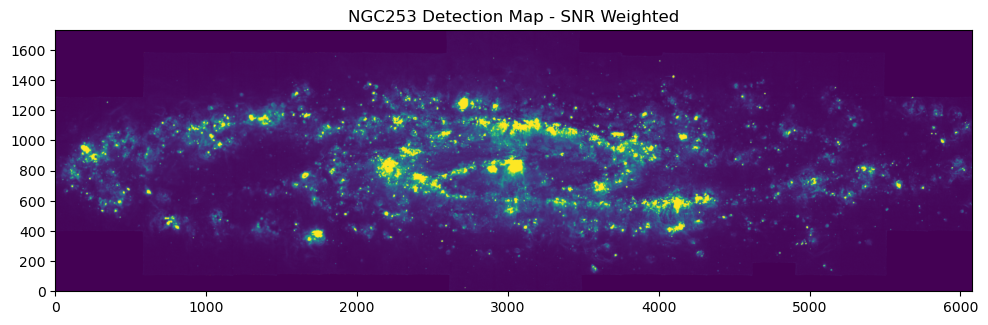

In [29]:
detection = det_map(ha, ha_err, oiii, oiii_err, sii, sii_err, snr_min=0.0, noise_method="median")
#detection[pn_mask] = 0.0
#plt.imshow(percentile_norm(oi))
plt.figure(figsize=(10, 5))
plt.imshow(percentile_norm(detection), origin="lower")
plt.title("NGC253 Detection Map - SNR Weighted")
plt.tight_layout()
plt.show()

In [30]:
segmentation_runs = {
    "1": {
        "dendro": (20.0, 10.0, 400),        # min_value, min_delta, min_npix
        "conv":   (150, 2.0, 0.4, 32, 1e-3) # npixels, smooth_sigma, threshold, nlevels, contrast
    },

    "2": {
        "dendro": (15.0, 10.0, 400),
        "conv":   (150, 2.0, 0.4, 32, 1e-3)},

    "3": {
        "dendro": (25.0, 10.0, 400),
        "conv":   (150, 2.0, 0.4, 32, 1e-3)},

    "4": {
        "dendro": (25.0, 5.0, 250),
        "conv":   (100, 3.0, 0.5, 32, 1e-3)},

    "5": {
        "dendro": (25.0, 10.0, 250),
        "conv":   (100, 3.0, 0.4, 32, 1e-4)},}

In [31]:
segmentation_results = {}

for run_name, pars in segmentation_runs.items():

    min_value, min_delta, min_npix = pars["dendro"]
    npixels, smooth_sigma, smooth_threshold, nlevels, contrast = pars["conv"]

    print(f"\nRunning: {run_name}")

    dendro_label, dendro_show = comp_dendro(
        detection,
        min_value,
        min_delta,
        min_npix)

    conv_label, conv_show = conv(
        dendro_label,
        detection,
        npixels,
        smooth_sigma,
        smooth_threshold,
        nlevels,
        contrast)

    dendro_data = get_label_array(dendro_label)
    conv_data = get_label_array(conv_label)

    segmentation_results[run_name] = {
        "params": pars,

        "dendro_label": dendro_label,
        "dendro_show": dendro_show,
        "dendro_data": dendro_data,

        "conv_label": conv_label,
        "conv_show": conv_show,
        "labels_data": conv_data,

        "n_dendro_regions": count_regions(dendro_data),
        "n_conv_regions": count_regions(conv_data)}

    print(
        f"{run_name}: "
        f"dendro = {count_regions(dendro_data)}, "
        f"conv = {count_regions(conv_data)}")


Running: 1
Astrodendro leaves count: 739


Deblending:   0%|          | 0/567 [00:00<?, ?it/s]

final deblended regions: 969
1: dendro = 739, conv = 969

Running: 2
Astrodendro leaves count: 827


Deblending:   0%|          | 0/636 [00:00<?, ?it/s]

final deblended regions: 1077
2: dendro = 827, conv = 1077

Running: 3
Astrodendro leaves count: 675


Deblending:   0%|          | 0/517 [00:00<?, ?it/s]

final deblended regions: 879
3: dendro = 675, conv = 879

Running: 4
Astrodendro leaves count: 1046


Deblending:   0%|          | 0/870 [00:00<?, ?it/s]

final deblended regions: 1327
4: dendro = 1046, conv = 1327

Running: 5
Astrodendro leaves count: 1043


Deblending:   0%|          | 0/792 [00:00<?, ?it/s]

final deblended regions: 1302
5: dendro = 1043, conv = 1302


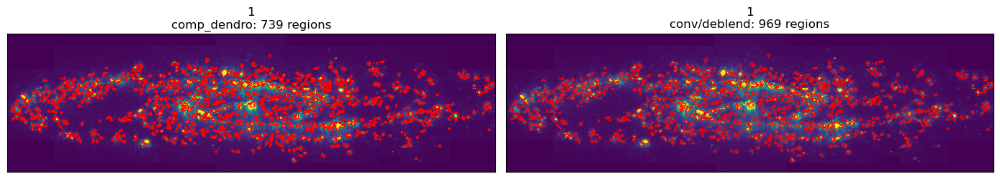

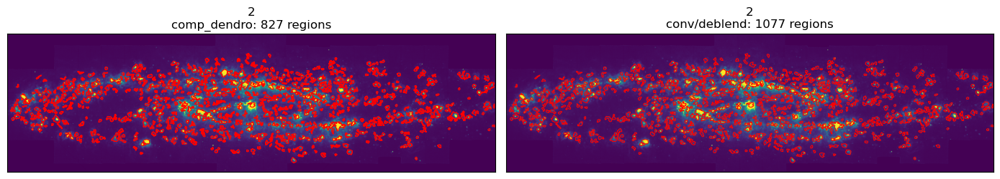

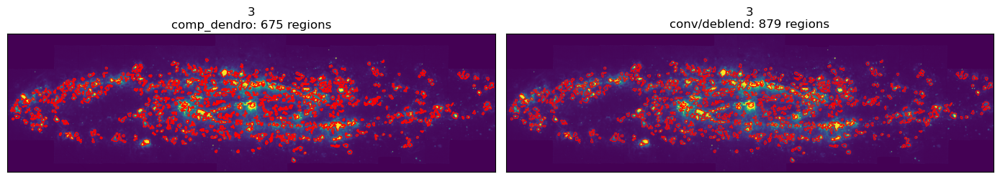

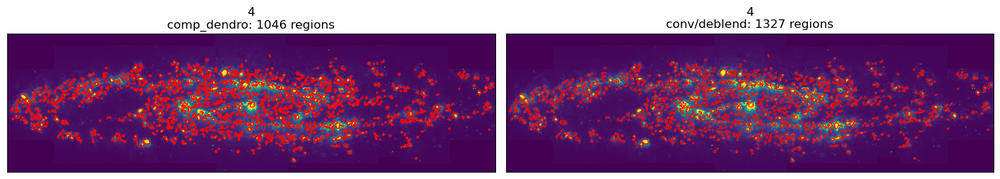

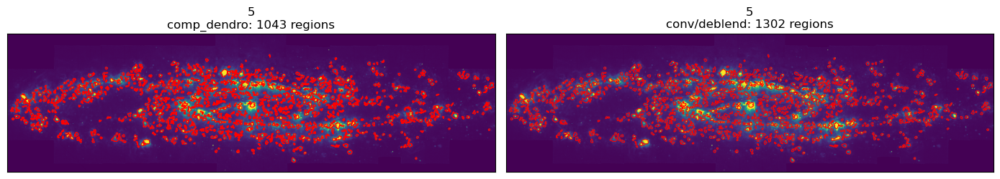

In [32]:
for run_name, result in segmentation_results.items():
    plot_segmentation_result(run_name, result, detection)

In [33]:
segmentation_summary = pd.DataFrame([{
        "run_name": run_name,

        "n_dendro_regions": result["n_dendro_regions"],
        "n_conv_regions": result["n_conv_regions"],

        "dendro_min_value": result["params"]["dendro"][0],
        "dendro_min_delta": result["params"]["dendro"][1],
        "dendro_min_npix": result["params"]["dendro"][2],

        "deblend_npixels": result["params"]["conv"][0],
        "smooth_sigma": result["params"]["conv"][1],
        "smooth_threshold": result["params"]["conv"][2],
        "deblend_nlevels": result["params"]["conv"][3],
        "deblend_contrast": result["params"]["conv"][4]}
    for run_name, result in segmentation_results.items()])

segmentation_summary

,run_name,n_dendro_regions,n_conv_regions,dendro_min_value,dendro_min_delta,dendro_min_npix,deblend_npixels,smooth_sigma,smooth_threshold,deblend_nlevels,deblend_contrast
0,1,739,969,20.0,10.0,400,150,2.0,0.4,32,0.0010
1,2,827,1077,15.0,10.0,400,150,2.0,0.4,32,0.0010
2,3,675,879,25.0,10.0,400,150,2.0,0.4,32,0.0010
3,4,1046,1327,25.0,5.0,250,100,3.0,0.5,32,0.0010
4,5,1043,1302,25.0,10.0,250,100,3.0,0.4,32,0.0001


In [34]:
selected_run = "5"
labels_data = segmentation_results[selected_run]["labels_data"]
selected_segmentation_params = segmentation_results[selected_run]["params"]

print("Selected run:", selected_run)
print("Final number of regions:", count_regions(labels_data))
print("Selected parameters:", selected_segmentation_params)

Selected run: 5
Final number of regions: 1302
Selected parameters: {'dendro': (25.0, 10.0, 250), 'conv': (100, 3.0, 0.4, 32, 0.0001)}


In [35]:
qa = make_segmentation_qa(
    labels_data=labels_data,
    detection=detection,
    ha=ha,
    ha_err=ha_err,
    oiii=oiii,
    oiii_err=oiii_err,
    sii=sii,
    sii_err=sii_err,
    wcs=wcs,
    pix_scale=pix_scale,
    pn_mask=None,)

In [36]:
qa[["npix",
    "r_eq_arcsec",
    "elongation",
    "det_peak",
    "det_median",
    "sn_ha",
    "sn_oiii",
    "sn_sii",
    "pn_overlap_frac"]].describe()

,npix,r_eq_arcsec,elongation,det_peak,det_median,sn_ha,sn_oiii,sn_sii,pn_overlap_frac
count,1302.000000,1302.000000,1302.000000,1302.000000,1302.000000,1302.000000,1302.000000,1302.000000,1302.0
mean,642.880952,2.697344,1.659281,432.161926,97.071272,1126.164622,179.653603,489.806340,0.0
std,541.754965,0.954175,0.511572,1260.052201,108.135146,879.416737,244.682270,390.706465,0.0
min,8.000000,0.319154,1.002881,33.402287,25.990194,29.465907,4.414970,44.188147,0.0
25%,333.250000,2.059871,1.297690,89.211770,41.842445,582.381665,72.260237,266.890846,0.0
50%,459.000000,2.417472,1.539916,177.651209,61.765796,857.152356,109.207076,386.750908,0.0
75%,734.000000,3.057054,1.872977,390.802515,107.883407,1376.146169,183.414449,578.662362,0.0
max,5706.000000,8.523558,4.999119,30353.244761,1543.209711,9426.909743,4305.688428,5254.822404,0.0


In [37]:
small_regions = qa.sort_values("npix").head(30)["region_id"].values
low_peak_regions = qa.sort_values("det_peak").head(30)["region_id"].values
elongated_regions = qa.sort_values("elongation", ascending=False).head(30)["region_id"].values

In [38]:
qa2 = qa.copy()

MIN_NPIX = 10
MIN_DET_PEAK = 3.0
MIN_SNR = 3.0
MAX_ELONGATION = 5.0
large_npix_cut = qa2["npix"].quantile(0.98)

qa2["flag_too_small"] = qa2["npix"] < MIN_NPIX
qa2["flag_low_peak"] = qa2["det_peak"] < MIN_DET_PEAK
qa2["flag_low_SNR"] = qa2["det_median"] < MIN_SNR
qa2["flag_edge_touching"] = qa2["edge_touching"]
qa2["flag_very_elongated"] = qa2["elongation"] > MAX_ELONGATION
qa2["flag_very_large"] = qa2["npix"] > large_npix_cut
qa2["flag_pn_overlap"] = qa2["pn_overlap_frac"] > 0


qa2["flag_bad_mask"] = (qa2["flag_too_small"] | qa2["flag_low_peak"] 
                        | qa2["flag_edge_touching"] | qa2["flag_low_SNR"] )

Total regions: 1302
Good candidates: 1301
Bad-mask candidates: 1
Very large regions: 27
Very elongated regions: 0


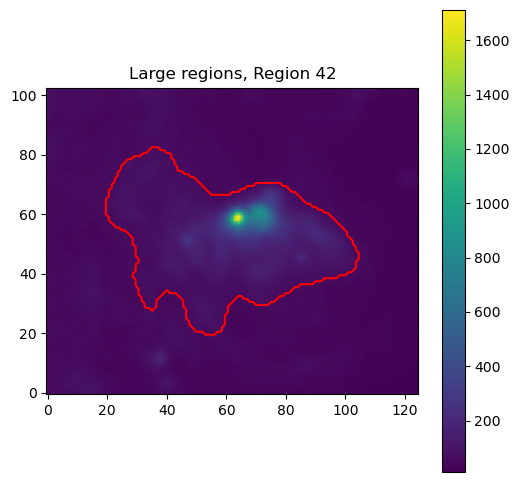

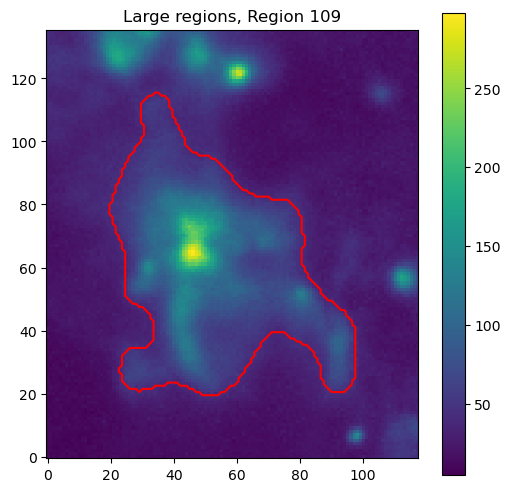

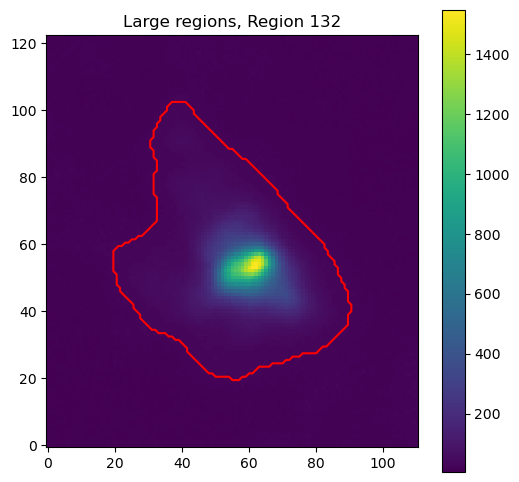

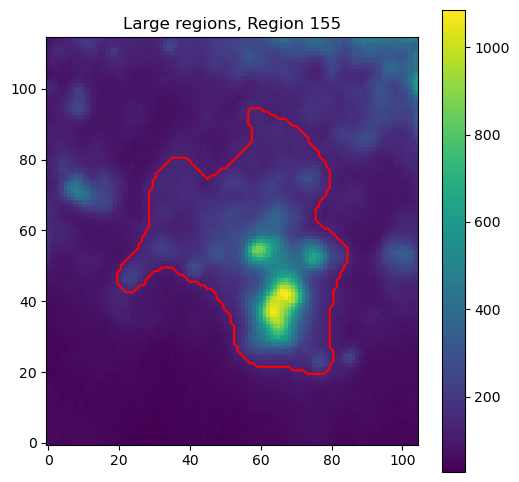

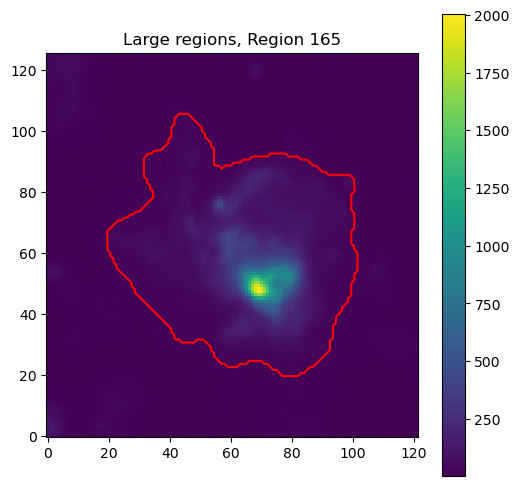

...

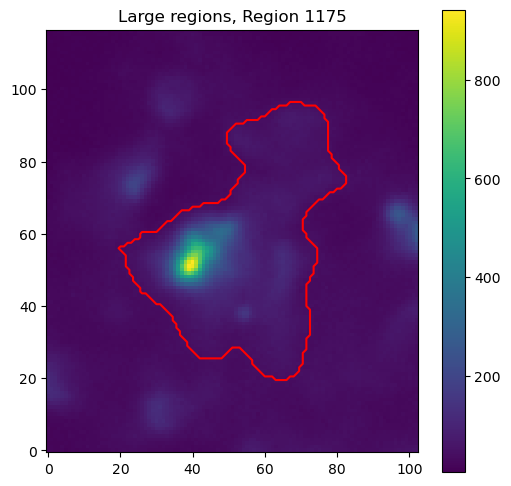

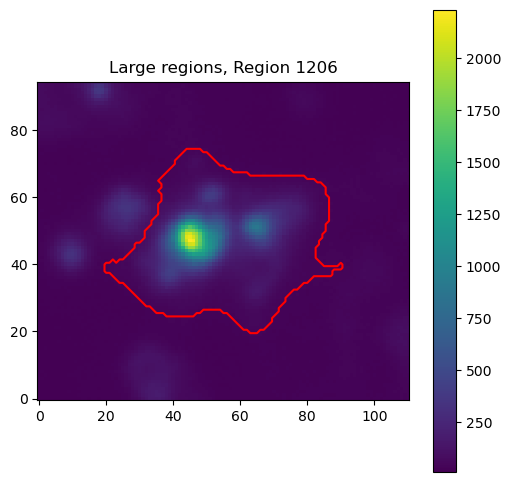

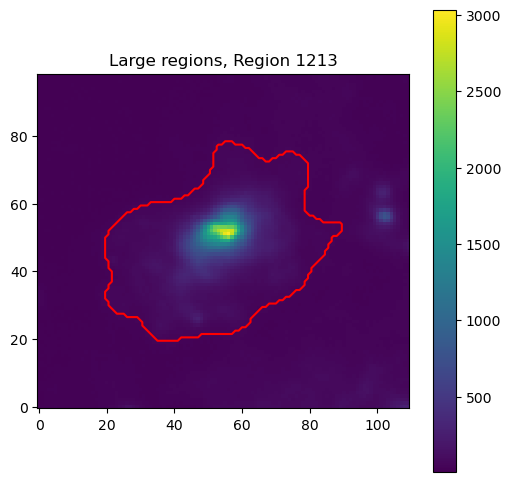

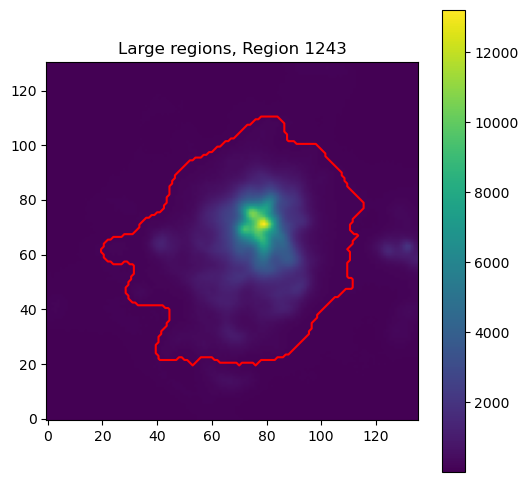

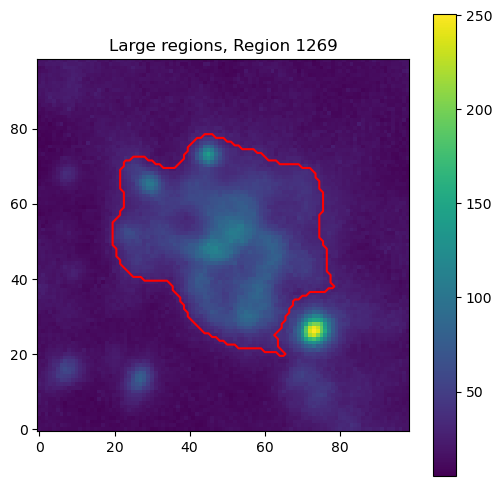

In [39]:
flag_cols = [c for c in qa2.columns if c.startswith("flag_")]

qa2[flag_cols].sum().sort_values(ascending=False)

good_candidate_ids = qa2.loc[~qa2["flag_bad_mask"], "region_id"].values
bad_candidate_ids = qa2.loc[qa2["flag_bad_mask"], "region_id"].values
large_ids = qa2.loc[qa2["flag_very_large"], "region_id"].values
elongated_ids = qa2.loc[qa2["flag_very_elongated"], "region_id"].values

print("Total regions:", len(qa2))
print("Good candidates:", len(good_candidate_ids))
print("Bad-mask candidates:", len(bad_candidate_ids))
print("Very large regions:", len(large_ids))
print("Very elongated regions:", len(elongated_ids))
'''
for rid in bad_candidate_ids:
    plot_single_region(detection, labels_data, rid, title_prefix="Bad mask",
                       contour_color="red", pad=20)
    
plot_region_contours(percentile_norm(detection), labels_data, large_ids, "Large region",
                     contour_color="cyan")
'''
for rid in large_ids:
    plot_single_region(detection, labels_data, rid, title_prefix="Large regions,", contour_color="red", pad=20)  

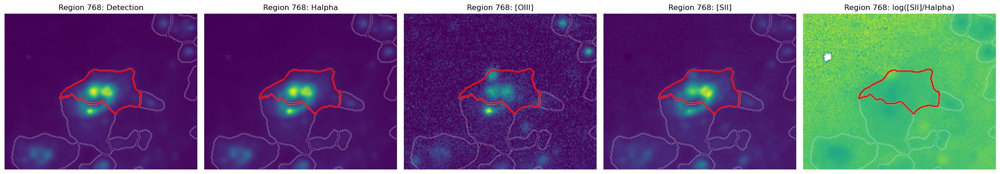

Nearby region IDs in crop:
[175 188 222 744 763 764 765 766 767 768 872 873 874]
Number of internal peaks above local 70th percentile: 2


In [40]:
from skimage.segmentation import find_boundaries
from skimage.feature import peak_local_max

def debug_region(region_id, labels_data, detection, ha, oiii, sii, pad=60):
    mask = labels_data == region_id

    if not np.any(mask):
        print(f"Region {region_id} not found.")
        return

    yy, xx = np.where(mask)
    y0, y1 = yy.min(), yy.max()
    x0, x1 = xx.min(), xx.max()

    y0p = max(0, y0 - pad)
    y1p = min(labels_data.shape[0], y1 + pad + 1)
    x0p = max(0, x0 - pad)
    x1p = min(labels_data.shape[1], x1 + pad + 1)

    slc = np.s_[y0p:y1p, x0p:x1p]

    det_crop = detection[slc]
    labels_crop = labels_data[slc]
    region_crop = labels_crop == region_id

    log_sii_ha = np.full_like(ha, np.nan, dtype=float)
    good = np.isfinite(sii) & np.isfinite(ha) & (sii > 0) & (ha > 0)
    log_sii_ha[good] = np.log10(sii[good] / ha[good])

    images = [
        (detection, "Detection"),
        (ha, "Halpha"),
        (oiii, "[OIII]"),
        (sii, "[SII]"),
        (log_sii_ha, "log([SII]/Halpha)")
    ]

    fig, axes = plt.subplots(1, len(images), figsize=(22, 5))

    for ax, (img, title) in zip(axes, images):
        img_crop = img[slc]
        ax.imshow(img_crop, origin="lower")
        
        all_bounds = find_boundaries(labels_crop, mode="outer")
        ax.contour(all_bounds.astype(float), levels=[0.5],
                   colors="white", linewidths=0.4, alpha=0.6)

        ax.contour(region_crop.astype(float), levels=[0.5],
                   colors="red", linewidths=2.0)

        ax.set_title(f"Region {region_id}: {title}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    local_ids = np.unique(labels_crop)
    local_ids = local_ids[local_ids > 0]
    print("Nearby region IDs in crop:")
    print(local_ids)

    # Count significant internal peaks inside the region
    smooth_det = ndi.gaussian_filter(det_crop, sigma=1.0)
    peaks = peak_local_max(
        smooth_det,
        labels=region_crop.astype(int),
        min_distance=max(2, int(psf_fwhm_pix)),
        threshold_abs=np.nanpercentile(smooth_det[region_crop], 70)
    )

    print(f"Number of internal peaks above local 70th percentile: {len(peaks)}")
debug_region(768, labels_data, detection, ha, oiii, sii)    

In [41]:
label_slices = ndi.find_objects(labels_data)

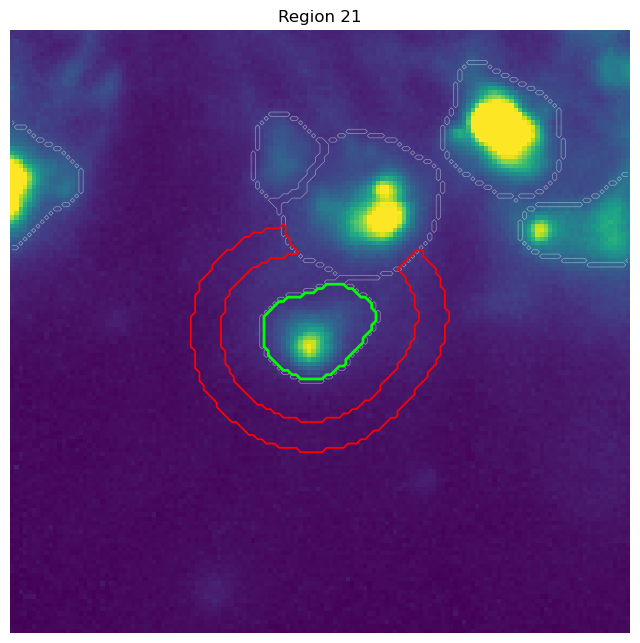

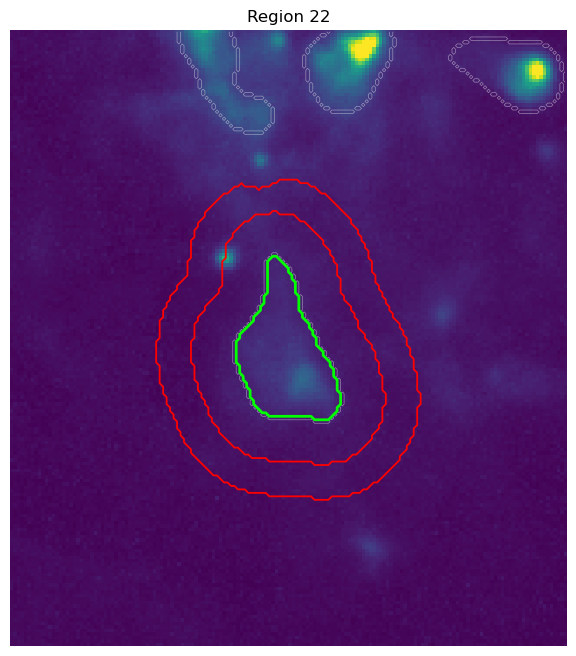

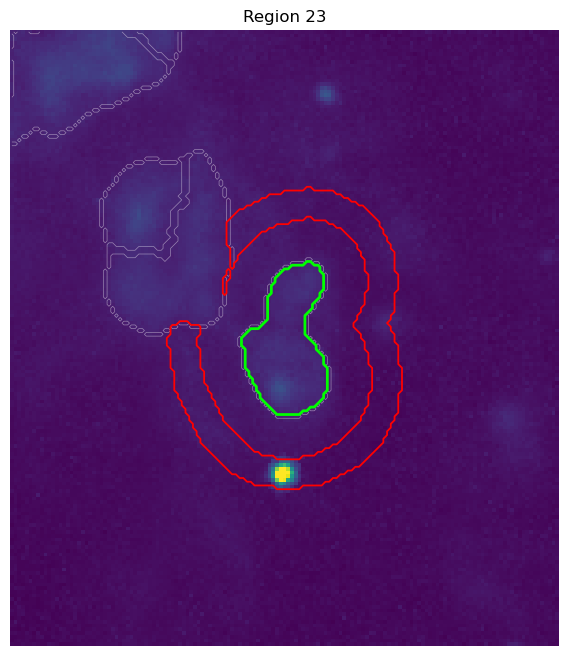

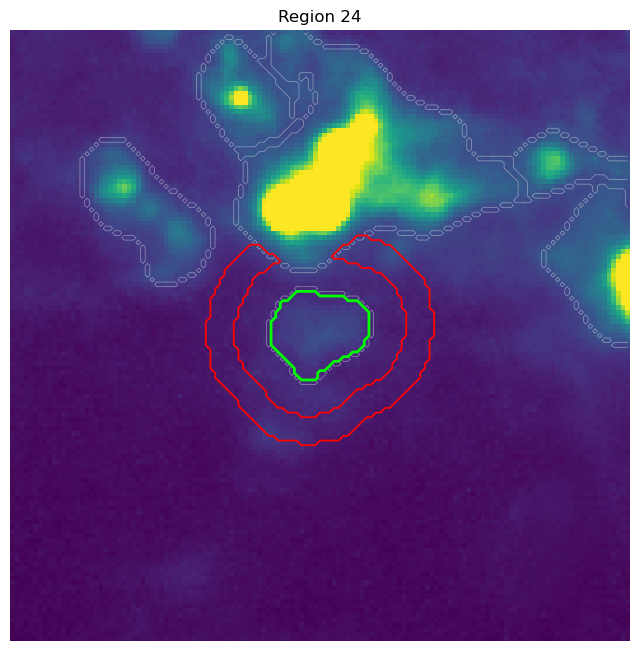

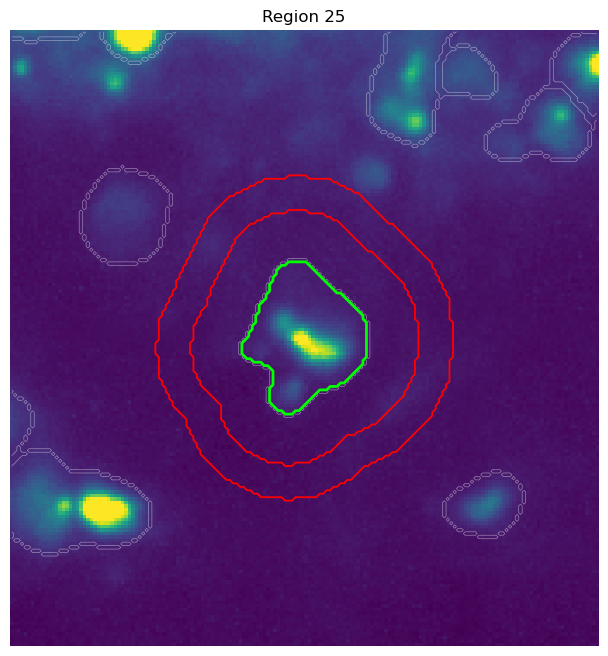

In [42]:
qa_lookup = qa2.set_index("region_id")

for test_id in good_candidate_ids[20:25]:
    src_crop, ann_crop, slc = make_local_annulus(
    labels_data, test_id, qa_lookup, label_slices, 
    inner_factor = 0.8, outer_factor = 1.4)

    show_source_annulus(percentile_norm(detection), src_crop,
    ann_crop, slc,
    labels_data=labels_data,
    title=f"Region {test_id}",
    show_all_regions=True, pad=40)

In [43]:
line_maps = {"ha": ha, "oiii": oiii, "sii": sii, "hb": hb, "nii": nii, "oi":oi}
line_err_maps = {"ha": ha_err, "oiii": oiii_err, "sii": sii_err, "hb": hb_err, "nii": nii_err, "oi": oi_err}

In [44]:
rows = []
for region_id in tqdm(good_candidate_ids):
    row = extract_region_fluxes(labels_data,
        region_id, qa_lookup, label_slices,
        line_maps, line_err_maps=line_err_maps,
        inner_factor=0.8, outer_factor=1.4,
        min_annulus_pix=30)
    if row is not None:
        rows.append(row)

flux_cat = pd.DataFrame(rows)
flux_cat.head()

  0%|          | 0/1301 [00:00<?, ?it/s]

/Users/golta/miniconda3/envs/thesis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/golta/miniconda3/envs/thesis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


,region_id,n_src_pix,n_ann_pix,flag_bad_annulus,ha_raw_flux,ha_raw_err,ha_raw_sn,ha_bg_level,ha_bg_sigma,ha_bg_flux,...,oi_raw_err,oi_raw_sn,oi_bg_level,oi_bg_sigma,oi_bg_flux,oi_bg_flux_err,oi_bg_fraction,oi_corr_flux,oi_corr_err,oi_corr_sn
0,1,417,1089,False,776457.500,949.594971,817.672302,121.971184,55.155600,50861.983635,...,369.887268,260.008636,25.451273,37.734057,10613.180826,597.457051,0.110354,85560.701986,702.688780,121.761873
1,2,304,739,False,540884.125,815.269592,663.442017,205.440811,61.815185,62454.006592,...,341.783600,572.765259,0.000000,1020.517810,0.000000,14299.571509,0.000000,195761.765625,14303.655524,13.686135
2,3,605,1528,False,1703703.000,1414.479492,1204.473511,247.651947,69.322760,149829.427948,...,471.232086,194.245087,20.939342,31.044668,12668.301635,602.048925,0.138399,78866.213990,764.540764,103.155015
3,4,977,2411,False,1174783.000,1189.821777,987.360474,179.493439,65.748908,175365.089630,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,722,1845,False,597657.500,877.125732,681.381775,157.852295,63.774468,113969.356934,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
suspicious_bg = flux_cat[
    (flux_cat["oiii_bg_fraction"] > 0.9) |
    (flux_cat["flag_bad_annulus"])]["region_id"].values

len(suspicious_bg)

94

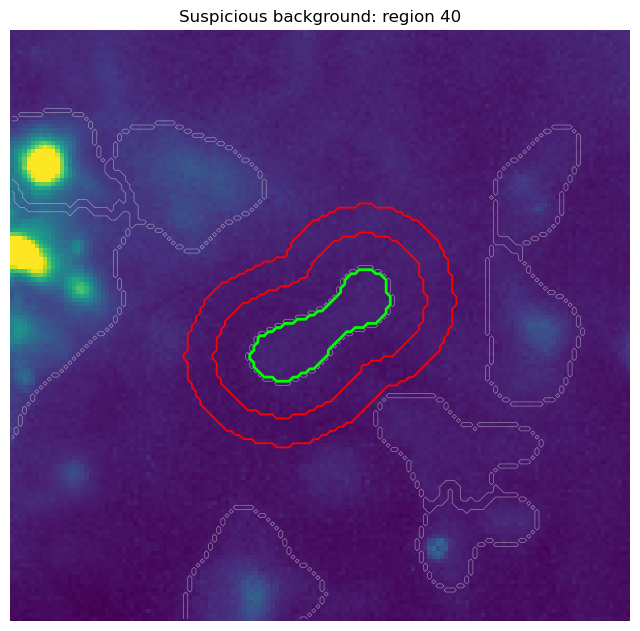

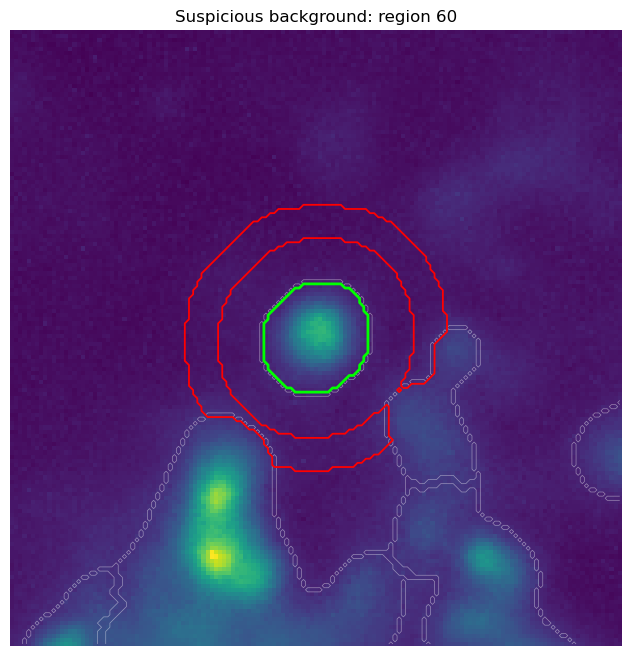

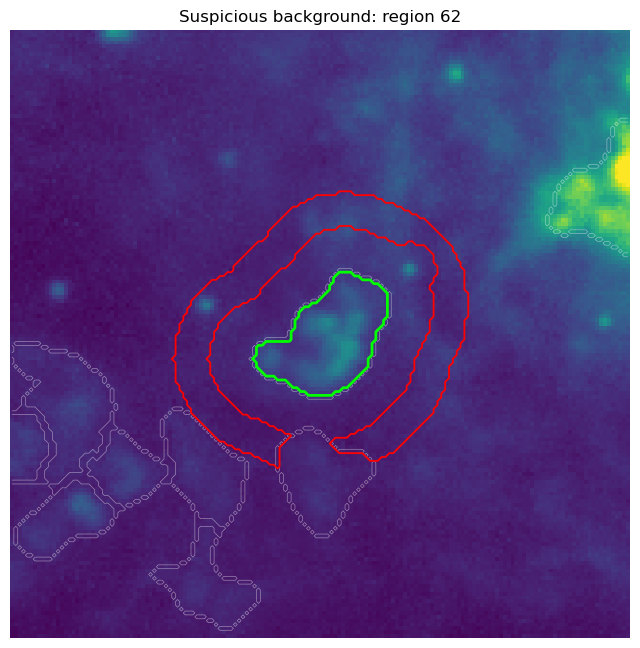

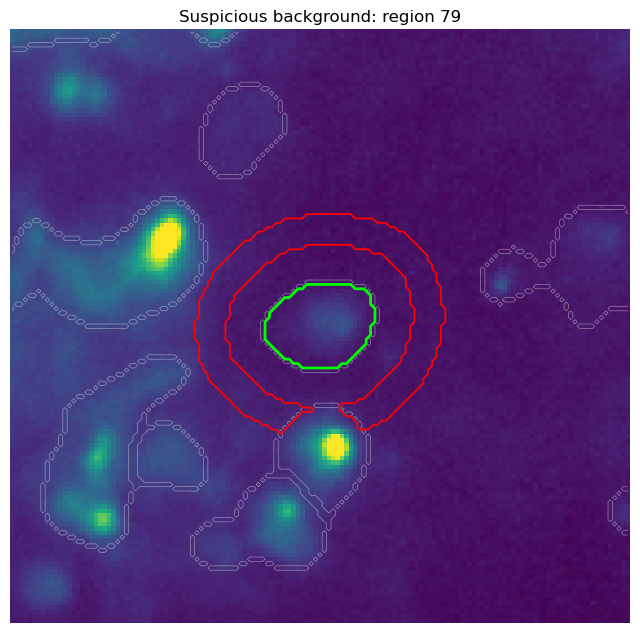

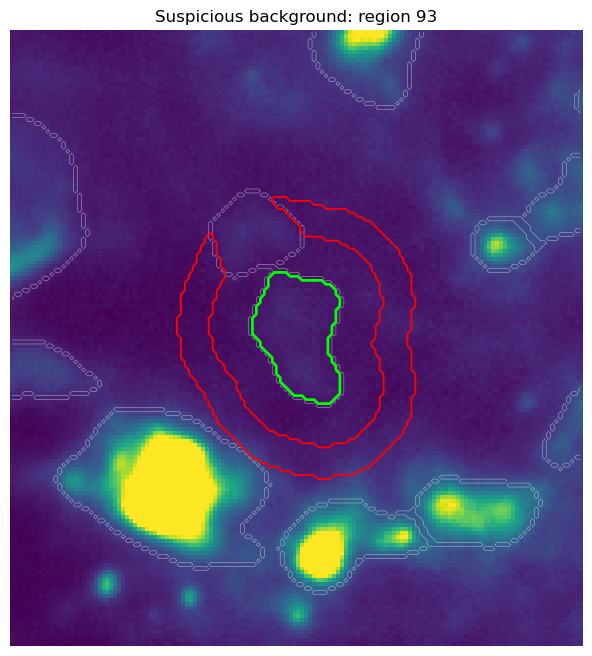

In [46]:
for region_id in suspicious_bg[:5]:
    src_crop, ann_crop, slc = make_local_annulus(labels_data,
        region_id, qa_lookup, label_slices, inner_factor = 0.8,
    outer_factor = 1.4)

    show_source_annulus(percentile_norm(detection),
        src_crop, ann_crop, slc,
        labels_data=labels_data,
        title=f"Suspicious background: region {region_id}",
        show_all_regions=True, pad=40)

In [47]:
cat = qa2.merge(flux_cat, on="region_id", how="left")

print("QA regions:", len(qa2))
print("Flux regions:", len(flux_cat))
print("Merged catalogue:", len(cat))

QA regions: 1302
Flux regions: 1301
Merged catalogue: 1302


In [48]:
cat["flag_high_ha_bg"] = cat["ha_bg_fraction"] > 0.9
cat["flag_high_oiii_bg"] = cat["oiii_bg_fraction"] > 0.9
cat["flag_high_sii_bg"] = cat["sii_bg_fraction"] > 0.9
cat["flag_high_oi_bg"] = cat["oi_bg_fraction"] > 0.9

cat["flag_any_high_bg"] = (cat["flag_high_ha_bg"] | cat["flag_high_oiii_bg"] |
                           cat["flag_high_sii_bg"] | cat["flag_bad_annulus"] | 
                           cat["flag_high_oi_bg"])

cat[["flag_bad_annulus", "flag_high_ha_bg",
     "flag_high_oiii_bg", "flag_high_sii_bg",
     "flag_any_high_bg"]].sum()

flag_bad_annulus       0
flag_high_ha_bg       11
flag_high_oiii_bg     94
flag_high_sii_bg      30
flag_any_high_bg     131
dtype: object

In [49]:
cat["log_sii_ha_raw"] = safe_log10_ratio(cat["sii_raw_flux"], cat["ha_raw_flux"])
cat["log_oiii_ha_raw"] = safe_log10_ratio(cat["oiii_raw_flux"], cat["ha_raw_flux"])
cat["log_sii_oiii_raw"] = safe_log10_ratio(cat["sii_raw_flux"], cat["oiii_raw_flux"])
cat["log_sii_ha_corr"] = safe_log10_ratio(cat["sii_corr_flux"], cat["ha_corr_flux"])
cat["log_oiii_ha_corr"] = safe_log10_ratio(cat["oiii_corr_flux"], cat["ha_corr_flux"])
cat["log_sii_oiii_corr"] = safe_log10_ratio(cat["sii_corr_flux"], cat["oiii_corr_flux"])
cat["log_oi_ha_raw"] = safe_log10_ratio(cat["oi_raw_flux"], cat["ha_raw_flux"])
cat["log_oi_ha_corr"] = safe_log10_ratio(cat["oi_corr_flux"], cat["ha_corr_flux"])

cat["log_nii_ha_raw"] = safe_log10_ratio(cat["nii_raw_flux"], cat["ha_raw_flux"])
cat["log_oiii_hb_raw"] = safe_log10_ratio(cat["oiii_raw_flux"], cat["hb_raw_flux"])
cat["log_nii_ha_corr"] = safe_log10_ratio(cat["nii_corr_flux"], cat["ha_corr_flux"])
cat["log_oiii_hb_corr"] = safe_log10_ratio(cat["oiii_corr_flux"], cat["hb_corr_flux"])

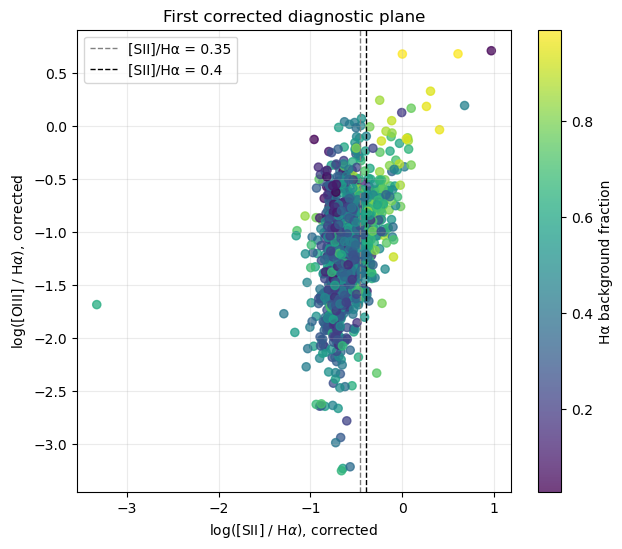

In [50]:
plot_cat = cat[(~cat["flag_bad_mask"]) &
    np.isfinite(cat["log_sii_ha_corr"]) &
    np.isfinite(cat["log_oiii_ha_corr"])].copy()

plt.figure(figsize=(7, 6))
plt.scatter(plot_cat["log_sii_ha_corr"], plot_cat["log_oiii_ha_corr"],
            s=35, alpha=0.75, c=plot_cat["ha_bg_fraction"])

plt.colorbar(label="Hα background fraction")

plt.axvline(np.log10(0.35), color="gray", linestyle="--", linewidth=1, label="[SII]/Hα = 0.35")
plt.axvline(np.log10(0.4), color="black", linestyle="--", linewidth=1, label="[SII]/Hα = 0.4")

plt.xlabel(r"log([SII] / H$\alpha$), corrected")
plt.ylabel(r"log([OIII] / H$\alpha$), corrected")
plt.title("First corrected diagnostic plane")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

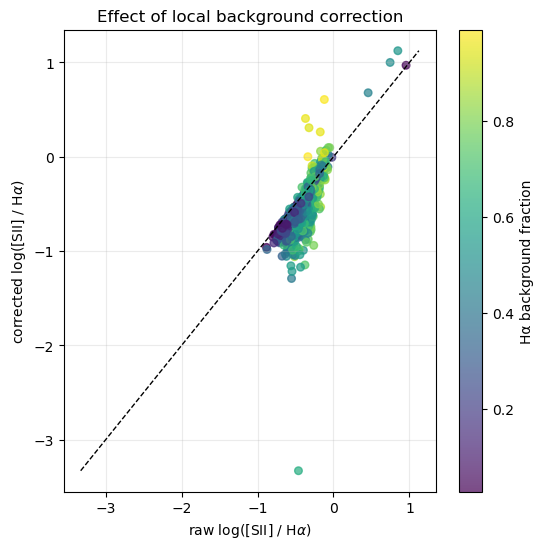

In [51]:
plt.figure(figsize=(6, 6))

valid = (np.isfinite(cat["log_sii_ha_raw"]) & np.isfinite(cat["log_sii_ha_corr"]))

plt.scatter(cat.loc[valid, "log_sii_ha_raw"], cat.loc[valid, "log_sii_ha_corr"],
            s=30, alpha=0.7, c=cat.loc[valid, "ha_bg_fraction"])

plt.colorbar(label="Hα background fraction")

lims = [np.nanmin([cat["log_sii_ha_raw"].min(), cat["log_sii_ha_corr"].min()]),
        np.nanmax([cat["log_sii_ha_raw"].max(), cat["log_sii_ha_corr"].max()])]

plt.plot(lims, lims, color="black", linestyle="--", linewidth=1)

plt.xlabel(r"raw log([SII] / H$\alpha$)")
plt.ylabel(r"corrected log([SII] / H$\alpha$)")
plt.title("Effect of local background correction")
plt.grid(alpha=0.25)
plt.show()

In [52]:
suspicious_ids = cat.loc[cat["flag_any_high_bg"], "region_id"].values

print("Suspicious/high-background regions:", len(suspicious_ids))
suspicious_ids[:30]

Suspicious/high-background regions: 131


array([ 40,  51,  60,  62,  79,  93,  97,  98, 105, 108, 119, 121, 122,
       125, 126, 128, 139, 140, 143, 167, 182, 192, 196, 202, 206, 211,
       214, 215, 216, 220], dtype=int32)

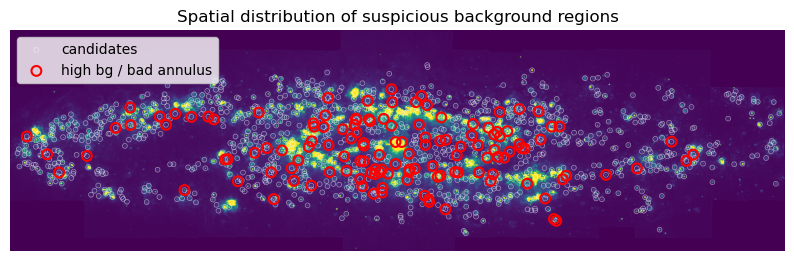

In [53]:
plt.figure(figsize=(10, 10))

plt.imshow(percentile_norm(detection), origin="lower")

plt.scatter(cat.loc[~cat["flag_bad_mask"], "x"], cat.loc[~cat["flag_bad_mask"], "y"],
            s=12, facecolors="none", edgecolors="white",
            linewidths=0.5, alpha=0.5, label="candidates")

sus = cat["flag_any_high_bg"] & (~cat["flag_bad_mask"])

plt.scatter(cat.loc[sus, "x"], cat.loc[sus, "y"],
            s=50, facecolors="none", edgecolors="red",
            linewidths=1.5, label="high bg / bad annulus")

plt.legend()
plt.title("Spatial distribution of suspicious background regions")
plt.axis("off")
plt.show()

In [54]:
cat2 = cat.copy()

cat2["sii_ha_corr"] = 10 ** cat2["log_sii_ha_corr"]
cat2["oiii_ha_corr"] = 10 ** cat2["log_oiii_ha_corr"]
cat2["sii_oiii_corr"] = 10 ** cat2["log_sii_oiii_corr"]
cat2["nii_ha_corr"] = 10 ** cat2["log_nii_ha_corr"]
cat2["oiii_hb_corr"] = 10 ** cat2["log_oiii_hb_corr"]
cat2["oi_ha_corr"] = 10 ** cat2["log_oi_ha_corr"]

cat2["ha_corr_sb"] = cat2["ha_corr_flux"] / cat2["area_arcsec2"]

positive_sb = cat2.loc[np.isfinite(cat2["ha_corr_sb"]) & (cat2["ha_corr_sb"] > 0), "ha_corr_sb"]

LOW_HA_SB_CUT = positive_sb.quantile(0.25)

print("Low Halpha surface brightness cut:", LOW_HA_SB_CUT)

Low Halpha surface brightness cut: 12857.970362008655


In [55]:
cat2["flag_ha_reliable"] = (
    np.isfinite(cat2["ha_corr_flux"]) &
    np.isfinite(cat2["ha_corr_sn"]) &
    (cat2["ha_corr_flux"] > 0) &
    (cat2["ha_corr_sn"] >= 3))

cat2["flag_sii_reliable"] = (
    np.isfinite(cat2["sii_corr_flux"]) &
    np.isfinite(cat2["sii_corr_sn"]) &
    (cat2["sii_corr_flux"] > 0) &
    (cat2["sii_corr_sn"] >= 3))

cat2["flag_oiii_reliable"] = (
    np.isfinite(cat2["oiii_corr_flux"]) &
    np.isfinite(cat2["oiii_corr_sn"]) &
    (cat2["oiii_corr_flux"] > 0) &
    (cat2["oiii_corr_sn"] >= 3))

cat2["flag_hb_reliable"] = (
    np.isfinite(cat2["hb_corr_flux"]) &
    np.isfinite(cat2["hb_corr_sn"]) &
    (cat2["hb_corr_flux"] > 0) &
    (cat2["hb_corr_sn"] >= 3))

cat2["flag_nii_reliable"] = (
    np.isfinite(cat2["nii_corr_flux"]) &
    np.isfinite(cat2["nii_corr_sn"]) &
    (cat2["nii_corr_flux"] > 0) &
    (cat2["nii_corr_sn"] >= 3))

cat2["flag_oi_reliable"] = (
    np.isfinite(cat2["oi_corr_flux"]) &
    np.isfinite(cat2["oi_corr_sn"]) &
    (cat2["oi_corr_flux"] > 0) &
    (cat2["oi_corr_sn"] >= 3))

cat2["flag_bpt_reliable"] = (
    cat2["flag_ha_reliable"] &
    cat2["flag_hb_reliable"] &
    cat2["flag_nii_reliable"] &
    cat2["flag_oiii_reliable"])

cat2["flag_oi_ha_reliable"] = cat2["flag_ha_reliable"] & cat2["flag_oi_reliable"]
cat2["flag_sii_ha_reliable"] = cat2["flag_ha_reliable"] & cat2["flag_sii_reliable"]
cat2["flag_oiii_ha_reliable"] = cat2["flag_ha_reliable"] & cat2["flag_oiii_reliable"]

cat2["bpt_tag"] = "unclassified_BPT"

bpt_ok = cat2["flag_bpt_reliable"]

cat2.loc[bpt_ok, "bpt_tag"] = [
    classify_bpt(n2, o3hb)
    for n2, o3hb in zip(
        cat2.loc[bpt_ok, "log_nii_ha_corr"],
        cat2.loc[bpt_ok, "log_oiii_hb_corr"])]

cat2["flag_bpt_hii"] = cat2["bpt_tag"].isin([
    "HII_BPT_clean",
    "HII_BPT_possible"])

cat2["flag_bpt_non_hii"] = cat2["bpt_tag"] == "non_HII_BPT"

#if BPT is unavailable do not automatically reject the region as HII
cat2["flag_bpt_allows_hii"] = ((~cat2["flag_bpt_reliable"]) | cat2["flag_bpt_hii"])

In [56]:
# Approximate line-ratio thresholds
SII_HA_DIG_LIKE = 0.35
SII_HA_SHOCK_LIKE = 0.40
OIII_HA_HIGH = 1.0
OI_HA_SHOCK_LIKE = 0.05
OI_HA_STRONG_SHOCK = 0.10

cat2["flag_high_oi"] = (
    cat2["flag_oi_ha_reliable"] &
    (cat2["oi_ha_corr"] >= OI_HA_SHOCK_LIKE))

cat2["flag_strong_oi"] = (
    cat2["flag_oi_ha_reliable"] &
    (cat2["oi_ha_corr"] >= OI_HA_STRONG_SHOCK))

# Size / shape flags
cat2["flag_compact"] = cat2["r_eq_arcsec"] <= 1.5 * psf_fwhm_arcsec
cat2["flag_low_ha_sb"] = cat2["ha_corr_sb"] < LOW_HA_SB_CUT

# Line-ratio flags
cat2["flag_hii_like_ratio"] = (
    cat2["flag_sii_ha_reliable"] &
    (cat2["sii_ha_corr"] < SII_HA_DIG_LIKE) &
    cat2["flag_bpt_allows_hii"])

cat2["flag_high_sii"] = (
    cat2["flag_sii_ha_reliable"] &
    (cat2["sii_ha_corr"] >= SII_HA_SHOCK_LIKE))

cat2["flag_moderate_sii"] = (
    cat2["flag_sii_ha_reliable"] &
    (cat2["sii_ha_corr"] >= SII_HA_DIG_LIKE) &
    (cat2["sii_ha_corr"] < SII_HA_SHOCK_LIKE))

cat2["flag_high_oiii"] = (
    cat2["flag_oiii_ha_reliable"] &
    (cat2["oiii_ha_corr"] >= OIII_HA_HIGH))

cat2["flag_bpt_shock_like"] = (
    cat2["flag_bpt_reliable"] &
    cat2["flag_bpt_non_hii"])

In [57]:
cat2["first_pass_tag"] = "unclassified_initial"
usable = (~cat2["flag_bad_mask"]) & (~cat2["flag_any_high_bg"])

'''
# High-OIII compact candidates: possible PN or compact high-excitation nebula
cat2.loc[(~cat2["flag_bad_mask"]) &
    (~cat2["flag_any_high_bg"]) &
    cat2["flag_high_oiii"] &
    cat2["flag_compact"],
    "first_pass_tag"] = "compact_high_oiii_candidate"
'''
# HII-like candidates
cat2.loc[
    usable &
    cat2["flag_hii_like_ratio"] &
    (~cat2["flag_low_ha_sb"]),
    "first_pass_tag"] = "hii_like_candidate"

# Moderate [SII]/Halpha, but still BPT-compatible with HII
cat2.loc[
    usable &
    cat2["flag_moderate_sii"] &
    cat2["flag_bpt_allows_hii"],
    "first_pass_tag"] = "transition_sii_candidate"

# DIG-like
cat2.loc[
    usable &
    (cat2["flag_high_sii"] | cat2["flag_high_oi"] | cat2["flag_bpt_shock_like"]) &
    (cat2["flag_low_ha_sb"] | cat2["flag_very_large"] | cat2["flag_very_elongated"]),
    "first_pass_tag"] = "dig_or_filament_candidate"

# SNR/shock-like
cat2.loc[
    usable &
    (~cat2["flag_low_ha_sb"]) &
    (cat2["flag_high_sii"] | cat2["flag_high_oi"] |
    (cat2["flag_bpt_shock_like"] &
    (cat2["flag_moderate_sii"] | cat2["flag_high_sii"] | cat2["flag_high_oi"]))), 
    "first_pass_tag"] = "snr_or_shock_candidate"

# Keep this LAST so nothing overwrites bad cases
cat2.loc[
    cat2["flag_bad_mask"] | cat2["flag_any_high_bg"],
    "first_pass_tag"] = "needs_inspection"

In [58]:
cat2["first_pass_tag"].value_counts()

first_pass_tag
hii_like_candidate           703
snr_or_shock_candidate       181
dig_or_filament_candidate    154
needs_inspection             132
unclassified_initial          82
transition_sii_candidate      50
Name: count, dtype: int64

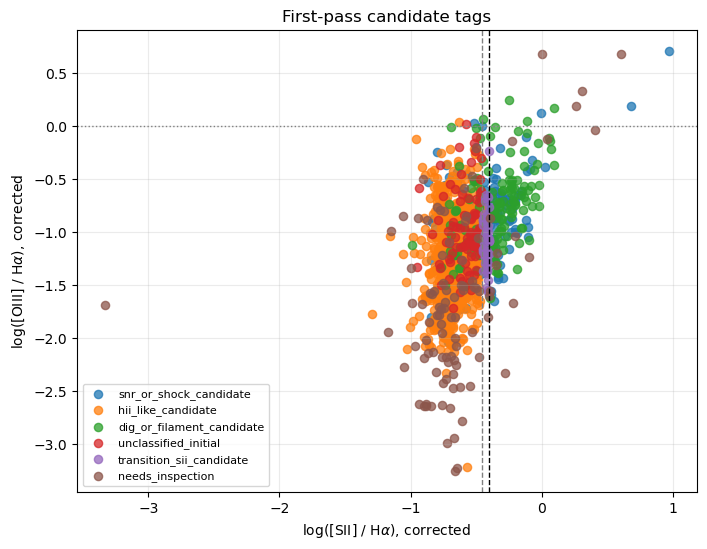

In [59]:
plot_cat = cat2[(~cat2["flag_bad_mask"]) &
    np.isfinite(cat2["log_sii_ha_corr"]) &
    np.isfinite(cat2["log_oiii_ha_corr"])].copy()

plt.figure(figsize=(8, 6))

for tag in plot_cat["first_pass_tag"].unique():
    sub = plot_cat[plot_cat["first_pass_tag"] == tag]

    plt.scatter(sub["log_sii_ha_corr"], sub["log_oiii_ha_corr"],
                s=35, alpha=0.75, label=tag)

plt.axvline(np.log10(0.35), color="gray", linestyle="--", linewidth=1)
plt.axvline(np.log10(0.40), color="black", linestyle="--", linewidth=1)
plt.axhline(np.log10(1.0), color="gray", linestyle=":", linewidth=1)

plt.xlabel(r"log([SII] / H$\alpha$), corrected")
plt.ylabel(r"log([OIII] / H$\alpha$), corrected")
plt.title("First-pass candidate tags")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.show()

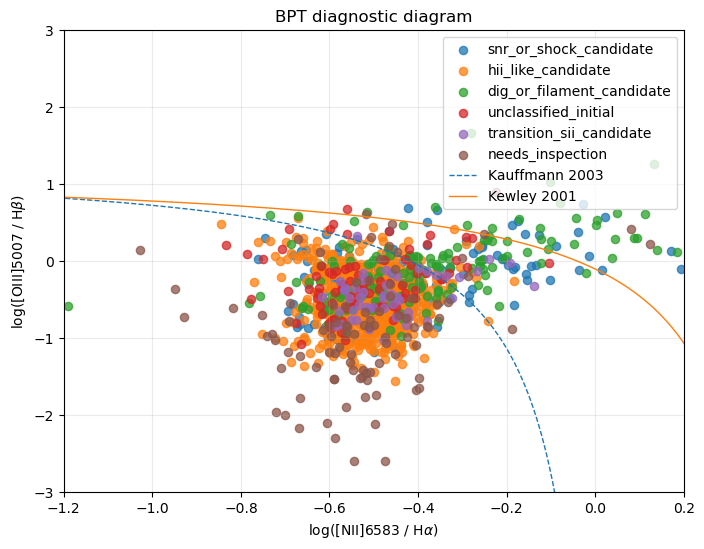

In [60]:
plot_cat = cat2[
    (~cat2["flag_bad_mask"]) &
    np.isfinite(cat2["log_nii_ha_corr"]) &
    np.isfinite(cat2["log_oiii_hb_corr"])].copy()

x = np.linspace(-2.0, 0.45, 400)

kauff_x = x[x < 0.05]
kauff_y = 0.61 / (kauff_x - 0.05) + 1.30

kewley_x = x[x < 0.47]
kewley_y = 0.61 / (kewley_x - 0.47) + 1.19

plt.figure(figsize=(8, 6))

for tag in plot_cat["first_pass_tag"].unique():
    sub = plot_cat[plot_cat["first_pass_tag"] == tag]
    plt.scatter(sub["log_nii_ha_corr"], sub["log_oiii_hb_corr"],
                s=35, alpha=0.75, label=tag)

plt.plot(kauff_x, kauff_y, "--", linewidth=1, label="Kauffmann 2003")
plt.plot(kewley_x, kewley_y, "-", linewidth=1, label="Kewley 2001")
plt.xlim(-1.2, 0.2)
plt.ylim(-3, 3)
plt.xlabel(r"log([NII]6583 / H$\alpha$)")
plt.ylabel(r"log([OIII]5007 / H$\beta$)")
plt.title("BPT diagnostic diagram")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [61]:
sn_ha = ha / ha_err
sn_oiii = oiii / oiii_err
sn_sii = sii / sii_err

log_sii_ha_map = safe_log10_ratio(sii, ha)
log_oiii_ha_map = safe_log10_ratio(oiii, ha)
log_sii_oiii_map = safe_log10_ratio(sii, oiii)

sn_min = 2.0

log_sii_ha_map[(sn_sii < sn_min) | (sn_ha < sn_min)] = np.nan
log_oiii_ha_map[(sn_oiii < sn_min) | (sn_ha < sn_min)] = np.nan
log_sii_oiii_map[(sn_sii < sn_min) | (sn_oiii < sn_min)] = np.nan

Region 1 | tag=snr_or_shock_candidate | [SII]/Ha=0.19 | [OIII]/Ha=0.43 | r=2.30" | 


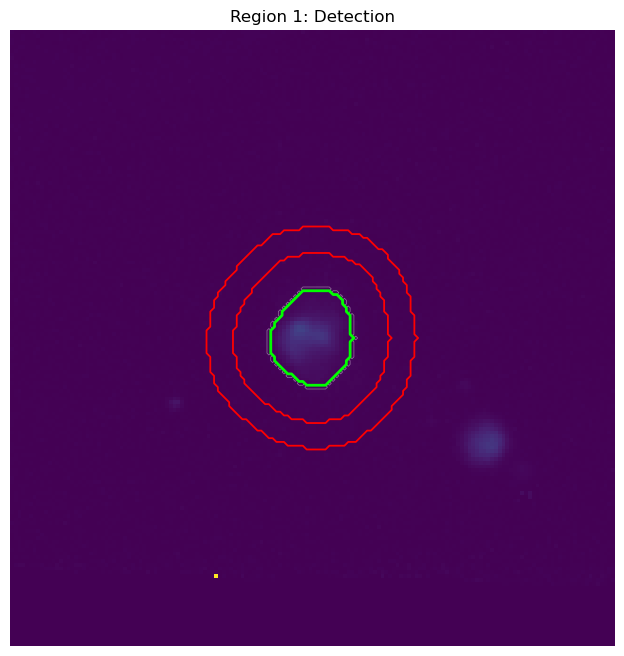

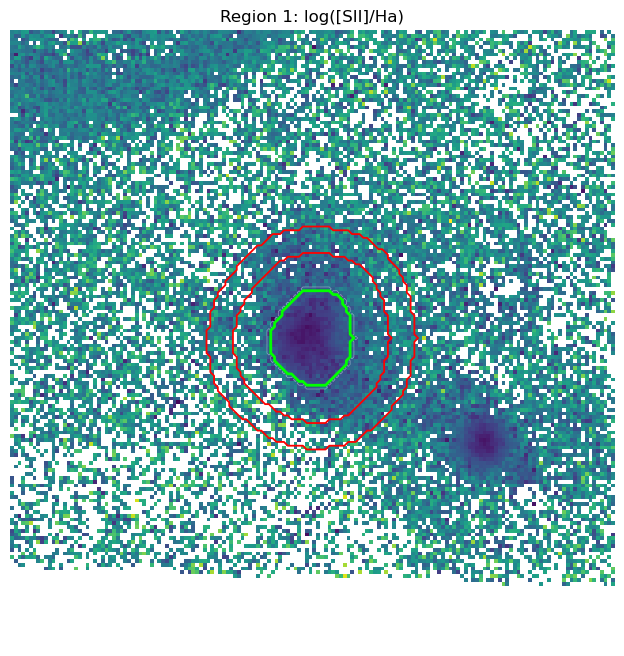

Region 2 | tag=snr_or_shock_candidate | [SII]/Ha=0.23 | [OIII]/Ha=0.10 | r=1.97" | 


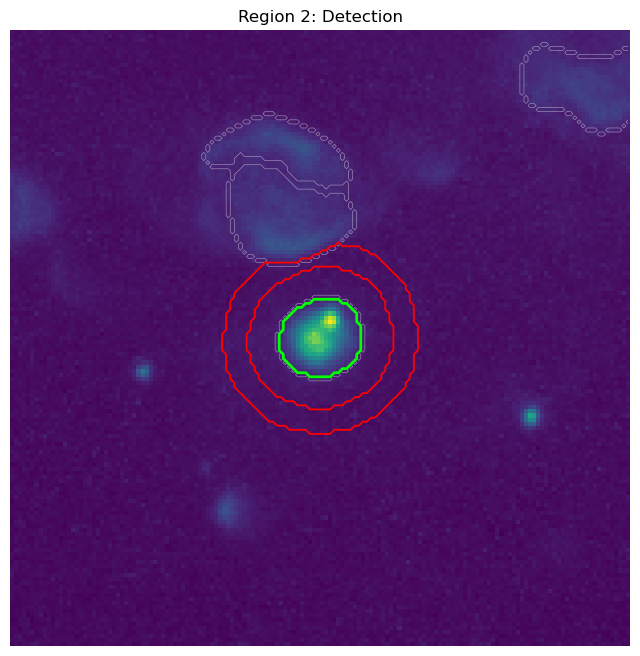

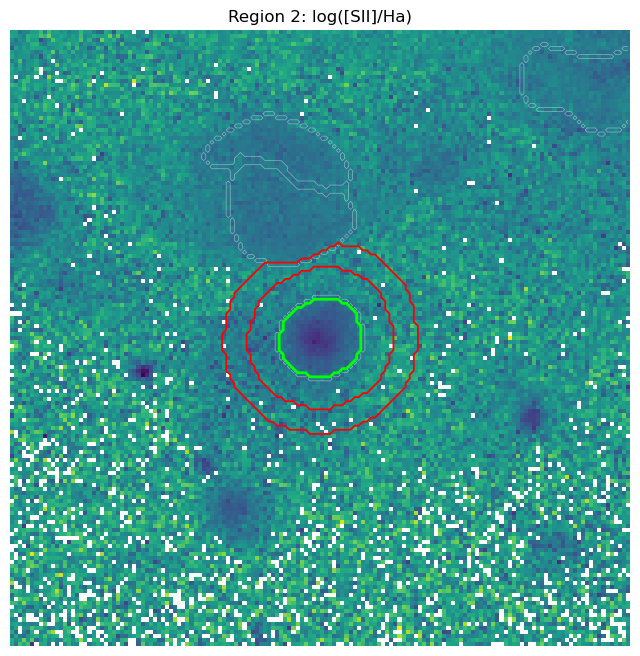

Region 3 | tag=snr_or_shock_candidate | [SII]/Ha=0.18 | [OIII]/Ha=0.20 | r=2.78" | 


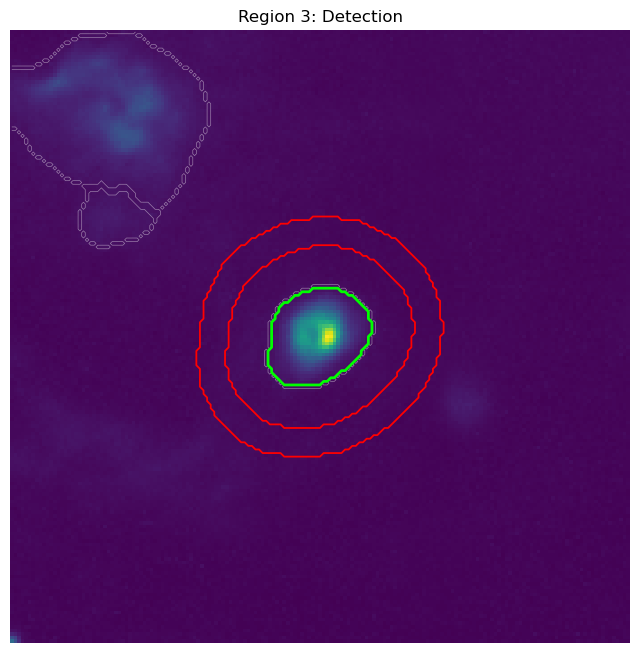

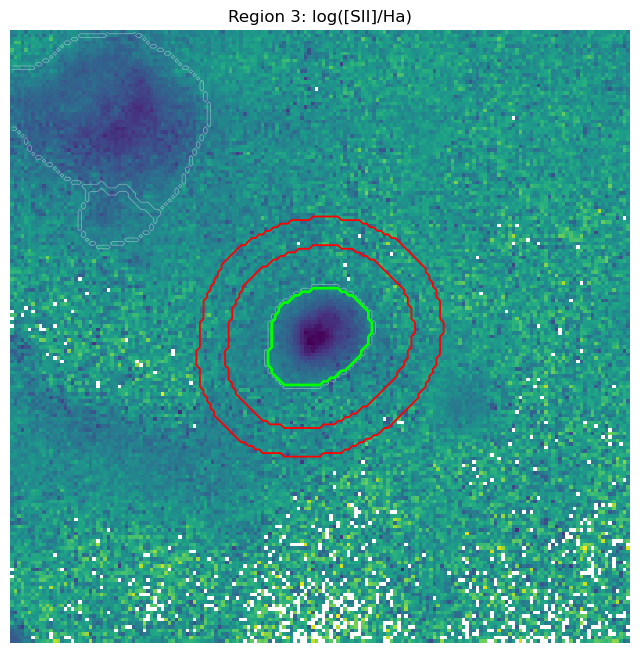

Region 9 | tag=snr_or_shock_candidate | [SII]/Ha=0.18 | [OIII]/Ha=0.28 | r=1.99" | 


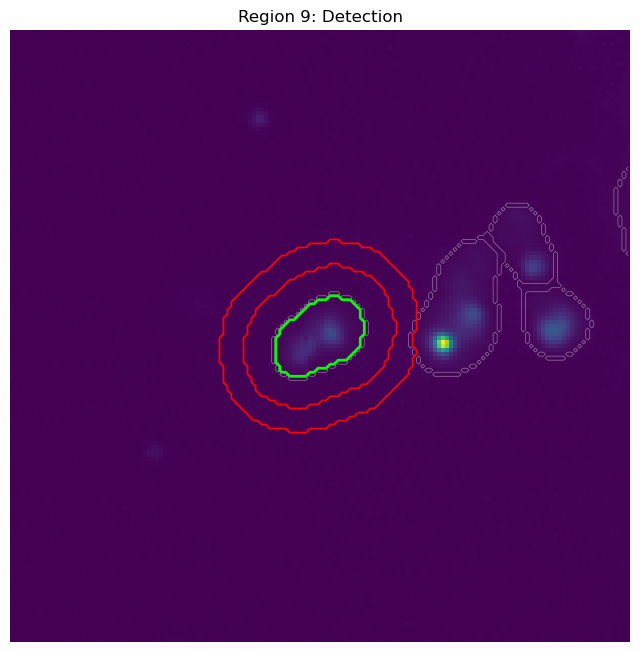

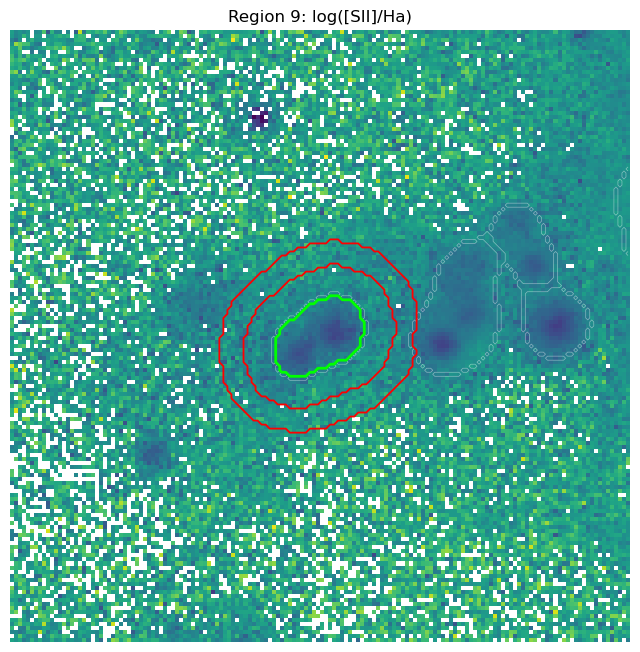

Region 10 | tag=snr_or_shock_candidate | [SII]/Ha=0.40 | [OIII]/Ha=0.21 | r=5.19" | 


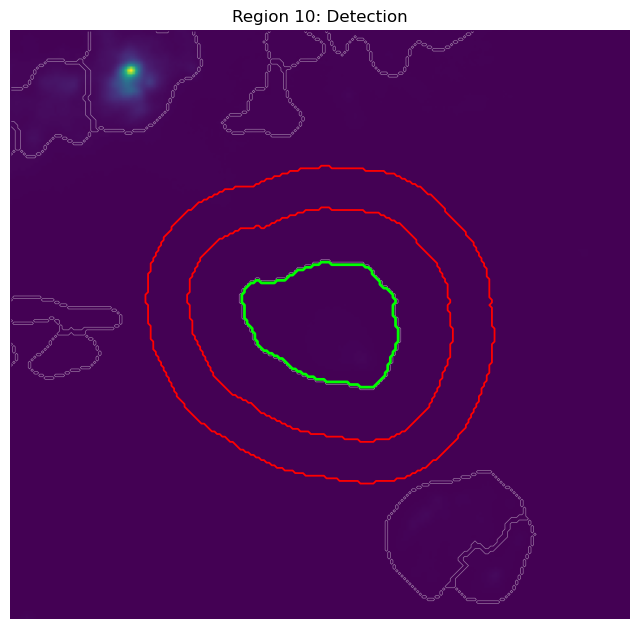

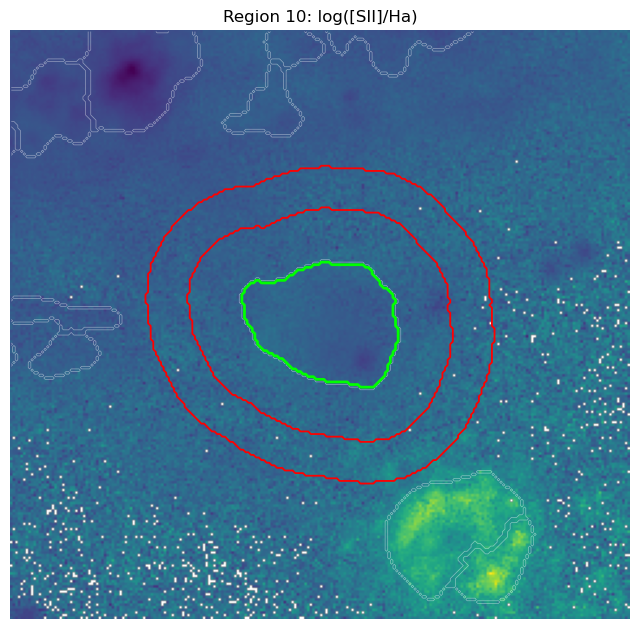

In [62]:
ids = cat2.loc[cat2["first_pass_tag"] == "snr_or_shock_candidate", "region_id"].values

for region_id in ids[:5]:

    src_crop, ann_crop, slc = make_local_annulus(
        labels_data, region_id, qa_lookup, label_slices,
        inner_factor = 0.8, outer_factor = 1.4)

    row = cat2.loc[cat2["region_id"] == region_id].iloc[0]

    print(f"Region {region_id} | "
        f"tag={row['first_pass_tag']} | "
        f"[SII]/Ha={row['sii_ha_corr']:.2f} | "
        f"[OIII]/Ha={row['oiii_ha_corr']:.2f} | "
        f"r={row['r_eq_arcsec']:.2f}\" | ")

    show_source_annulus(detection,
        src_crop,
        ann_crop,
        slc,
        labels_data=labels_data,
        title=f"Region {region_id}: Detection",
        show_all_regions=True,
        pad=50)

    show_source_annulus(log_sii_ha_map,
        src_crop,
        ann_crop,
        slc,
        labels_data=labels_data,
        title=f"Region {region_id}: log([SII]/Ha)",
        show_all_regions=True,
        pad=50)

Region 4 | tag=hii_like_candidate | [SII]/Ha=0.28 | [OIII]/Ha=0.38 | r=3.53" | 


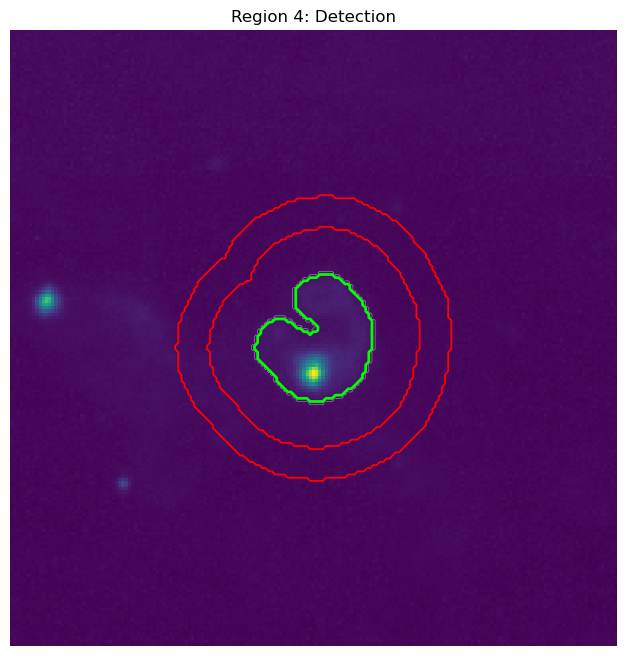

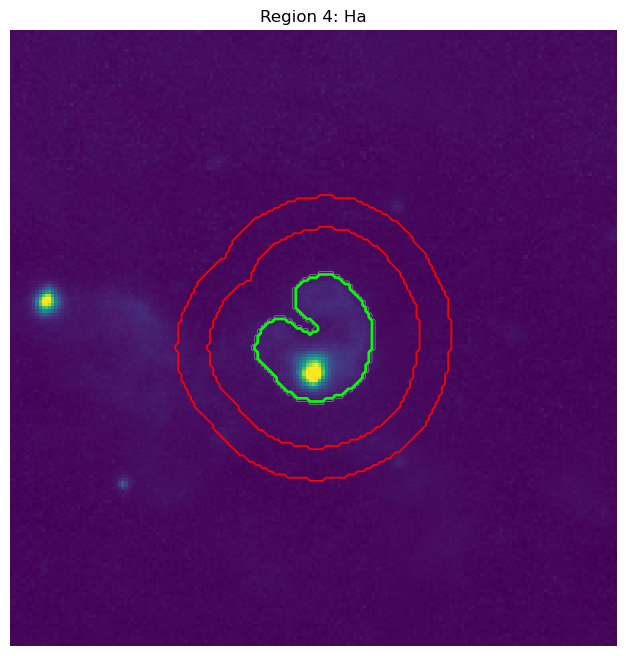

Region 5 | tag=hii_like_candidate | [SII]/Ha=0.29 | [OIII]/Ha=0.04 | r=3.03" | 


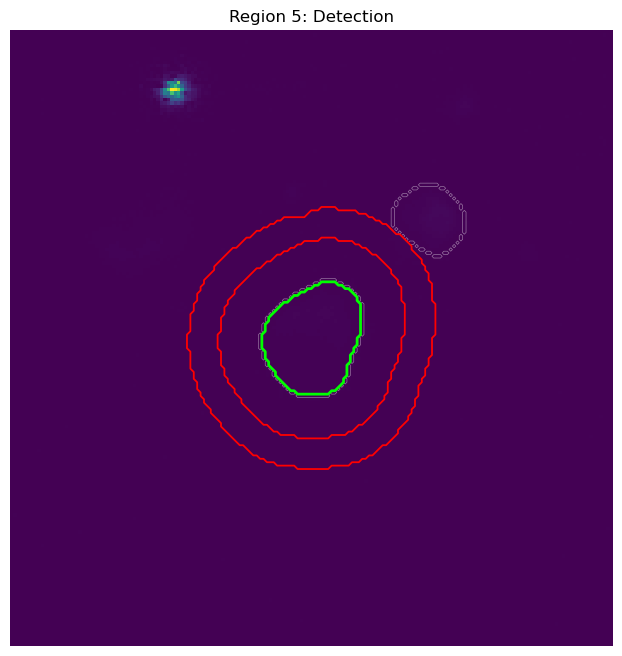

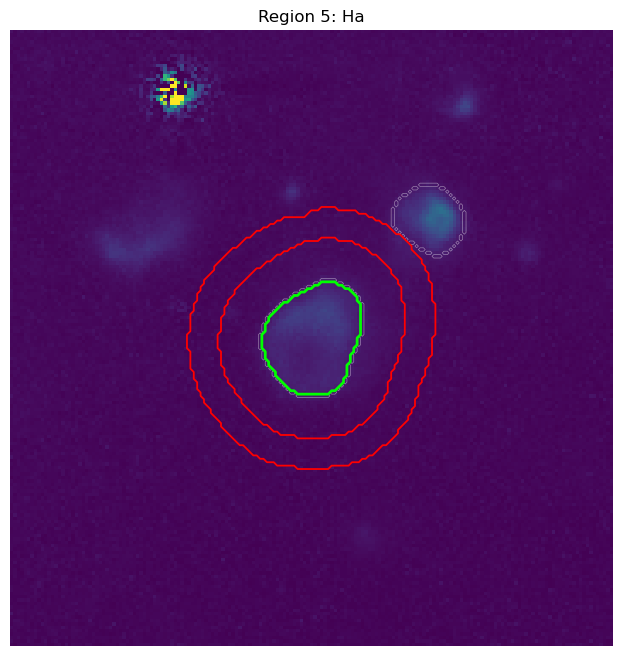

Region 7 | tag=hii_like_candidate | [SII]/Ha=0.24 | [OIII]/Ha=0.03 | r=1.94" | 


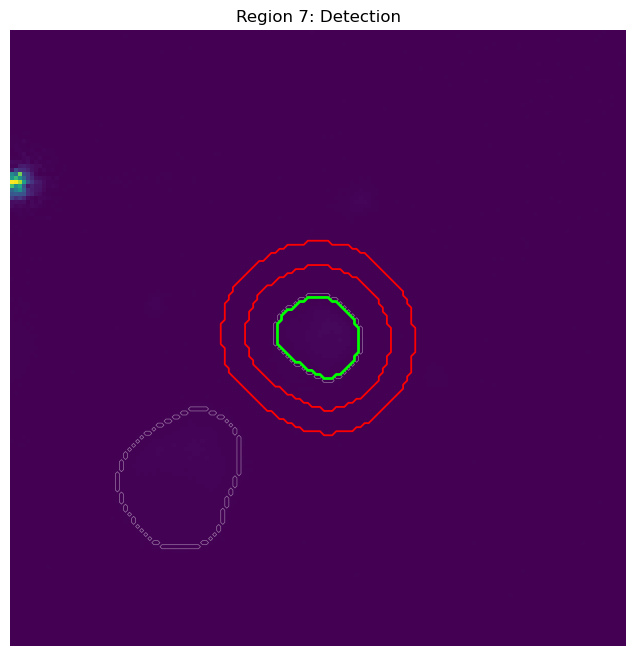

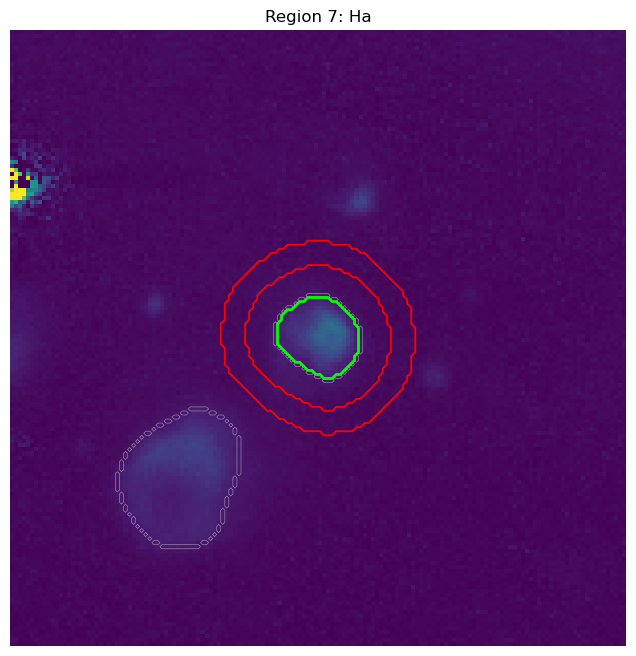

Region 17 | tag=hii_like_candidate | [SII]/Ha=0.30 | [OIII]/Ha=0.06 | r=3.16" | 


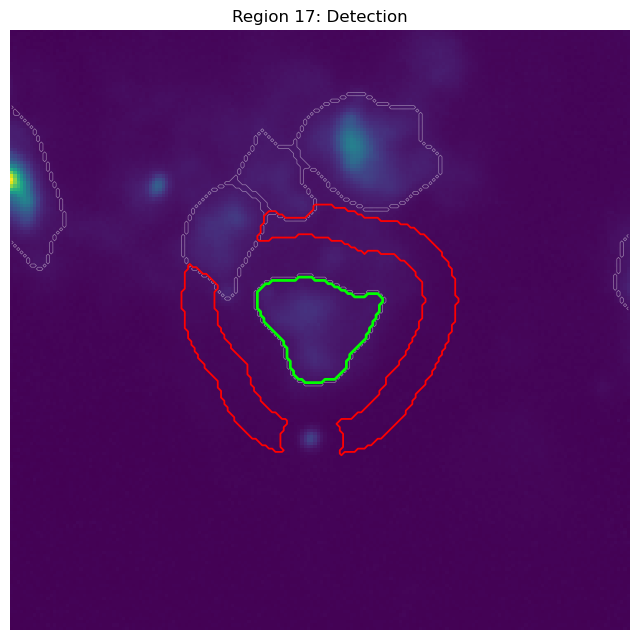

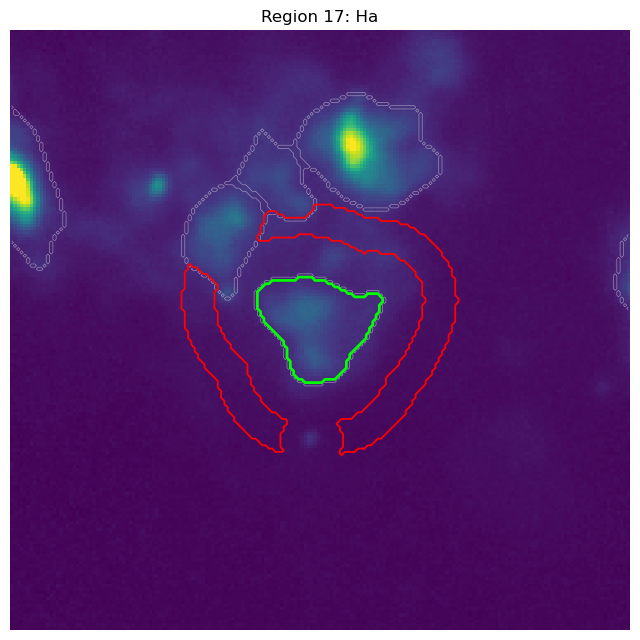

Region 18 | tag=hii_like_candidate | [SII]/Ha=0.23 | [OIII]/Ha=0.12 | r=1.91" | 


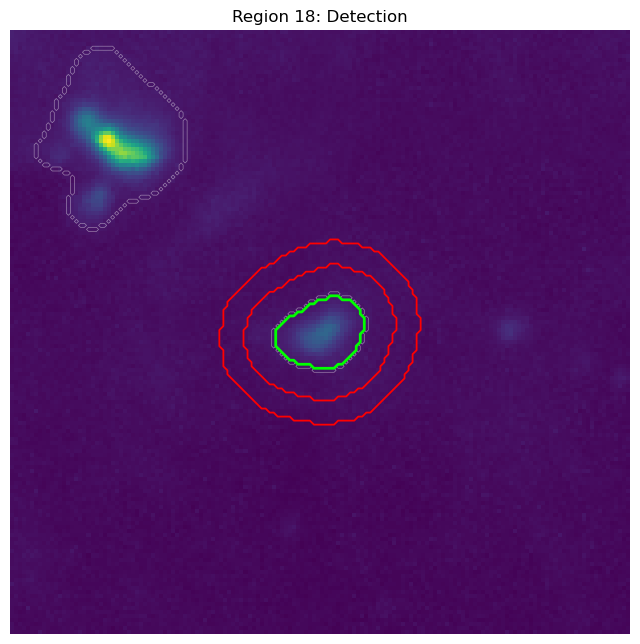

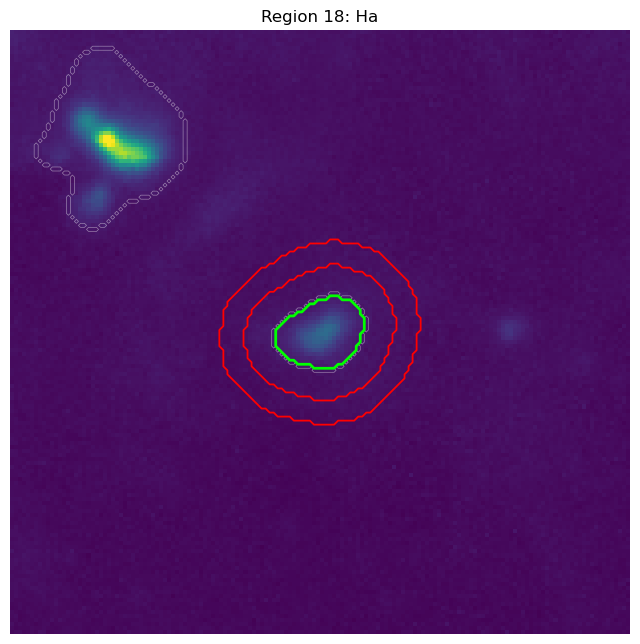

In [63]:
ids = cat2.loc[cat2["first_pass_tag"] == "hii_like_candidate", "region_id"].values

for region_id in ids[:5]:

    src_crop, ann_crop, slc = make_local_annulus(
        labels_data,
        region_id,
        qa_lookup,
        label_slices,
    inner_factor = 0.8,
    outer_factor = 1.4)

    row = cat2.loc[cat2["region_id"] == region_id].iloc[0]

    print(f"Region {region_id} | "
        f"tag={row['first_pass_tag']} | "
        f"[SII]/Ha={row['sii_ha_corr']:.2f} | "
        f"[OIII]/Ha={row['oiii_ha_corr']:.2f} | "
        f"r={row['r_eq_arcsec']:.2f}\" | ")

    show_source_annulus(detection,
        src_crop,
        ann_crop,
        slc,
        labels_data=labels_data,
        title=f"Region {region_id}: Detection",
        show_all_regions=True,
        pad=50)

    show_source_annulus(percentile_norm(ha),
        src_crop,
        ann_crop,
        slc,
        labels_data=labels_data,
        title=f"Region {region_id}: Ha",
        show_all_regions=True,
        pad=50)

Region 6 | tag=dig_or_filament_candidate | [SII]/Ha=0.71 | [OIII]/Ha=0.24 | r=2.35" | 


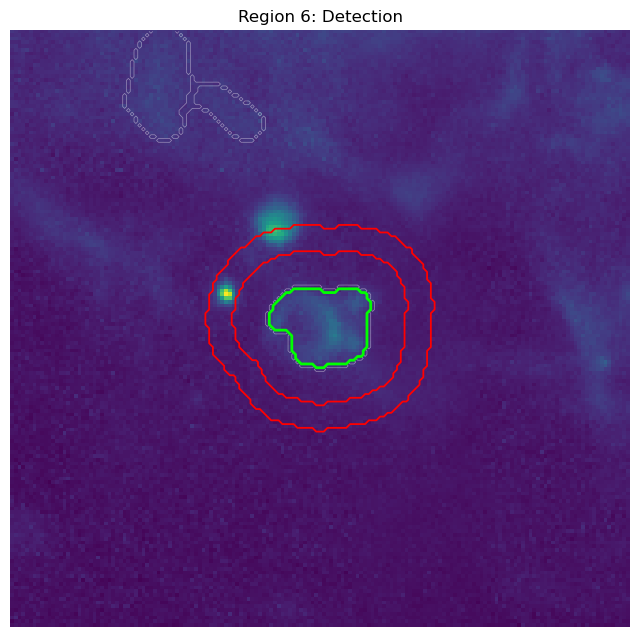

Region 8 | tag=dig_or_filament_candidate | [SII]/Ha=0.41 | [OIII]/Ha=0.80 | r=2.59" | 


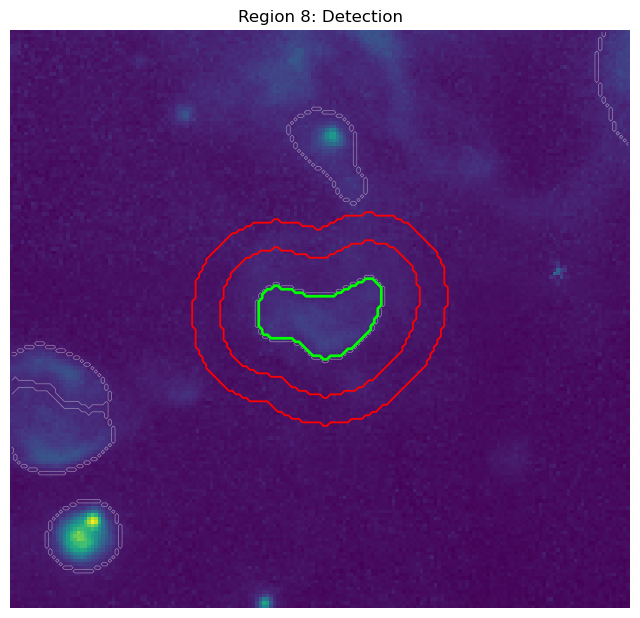

Region 13 | tag=dig_or_filament_candidate | [SII]/Ha=0.33 | [OIII]/Ha=0.07 | r=1.94" | 


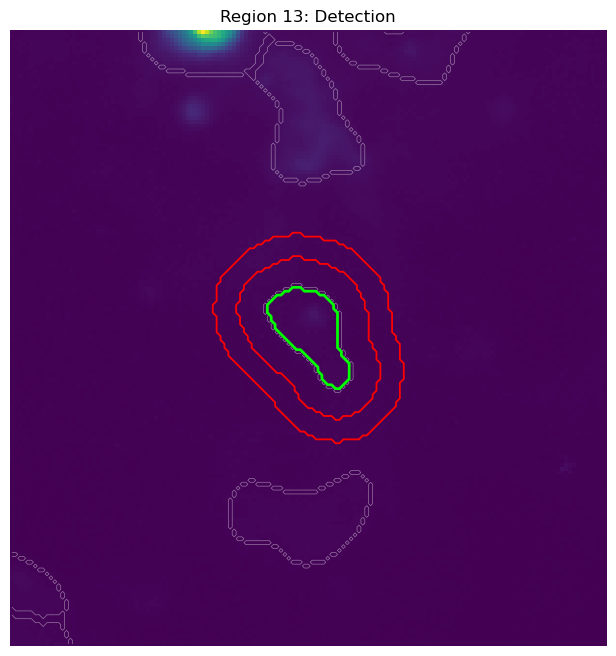

Region 16 | tag=dig_or_filament_candidate | [SII]/Ha=0.36 | [OIII]/Ha=1.17 | r=3.50" | 


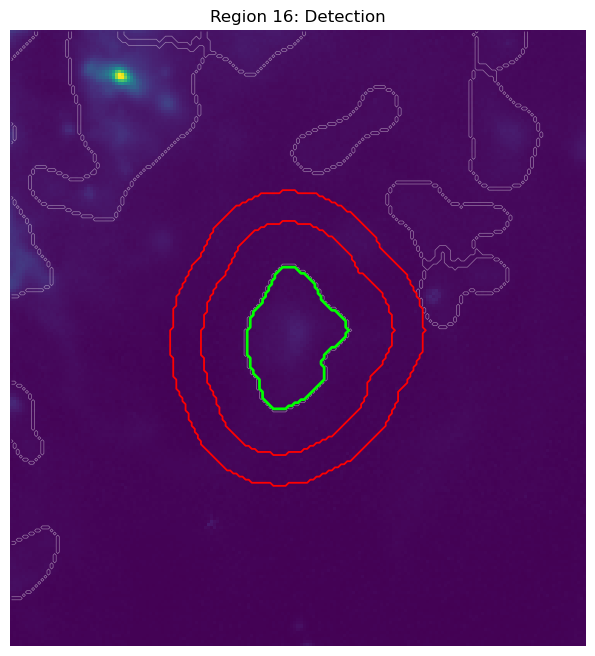

Region 19 | tag=dig_or_filament_candidate | [SII]/Ha=0.30 | [OIII]/Ha=0.30 | r=1.92" | 


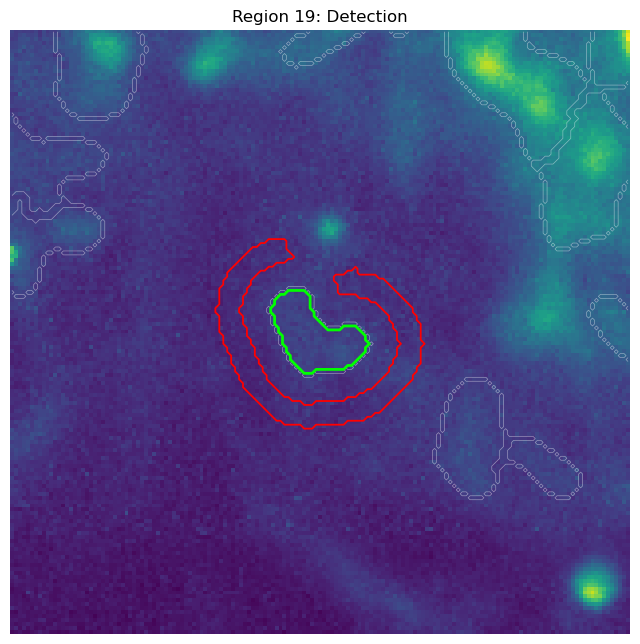

In [64]:
ids = cat2.loc[cat2["first_pass_tag"] == "dig_or_filament_candidate", "region_id"].values

for region_id in ids[:5]:

    src_crop, ann_crop, slc = make_local_annulus(
        labels_data,
        region_id,
        qa_lookup,
        label_slices,
    inner_factor = 0.8,
    outer_factor = 1.4)

    row = cat2.loc[cat2["region_id"] == region_id].iloc[0]

    print(f"Region {region_id} | "
        f"tag={row['first_pass_tag']} | "
        f"[SII]/Ha={row['sii_ha_corr']:.2f} | "
        f"[OIII]/Ha={row['oiii_ha_corr']:.2f} | "
        f"r={row['r_eq_arcsec']:.2f}\" | ")

    show_source_annulus(detection,
        src_crop,
        ann_crop,
        slc,
        labels_data=labels_data,
        title=f"Region {region_id}: Detection",
        show_all_regions=True,
        pad=50)

In [83]:
out_dir = Path("./results")
out_dir.mkdir(parents=True, exist_ok=True)

#final catalogue
cat2.to_pickle(out_dir / "first_pass_catalog.pkl")
cat2.to_csv(out_dir / "first_pass_catalog.csv", index=False)

qa2.to_pickle(out_dir / "qa_catalog.pkl")
flux_cat.to_pickle(out_dir / "flux_catalog.pkl")

# segmentation map
seg_header = header.copy()
seg_header["BUNIT"] = "label"
seg_header["COMMENT"] = "0 = background; positive integers = region IDs"

fits.writeto(
    out_dir / "labels_data.fits",
    labels_data.astype(np.int32),
    seg_header,
    overwrite=True)

# useful images
fits.writeto(
    out_dir / "detection.fits",
    detection.astype(np.float32),
    header,
    overwrite=True)

fits.writeto(
    out_dir / "pn_mask.fits",
    pn_mask.astype(np.uint8),
    header,
    overwrite=True)

# tag counts
tag_counts = (
    cat2["first_pass_tag"]
    .value_counts()
    .rename_axis("first_pass_tag")
    .reset_index(name="n_regions"))

tag_counts.to_csv(out_dir / "first_pass_tag_counts.csv", index=False)


# parameters / thresholds used
metadata = {
    "selected_segmentation_run": selected_run,
    "selected_segmentation_params": selected_segmentation_params,
    "tested_segmentation_runs": segmentation_summary.to_dict(orient="records"),
    "final_n_regions": int(labels_data.max()),
        
    "annulus_inner_factor": 0.8,
    "annulus_outer_factor": 1.4,
    "min_annulus_pix": 30,

    "pix_scale_arcsec": float(pix_scale),
    "psf_fwhm_arcsec": float(psf_fwhm_arcsec),

    "LOW_HA_SB_CUT": float(LOW_HA_SB_CUT),
    "SII_HA_DIG_LIKE": float(SII_HA_DIG_LIKE),
    "SII_HA_SHOCK_LIKE": float(SII_HA_SHOCK_LIKE),
    "OIII_HA_HIGH": float(OIII_HA_HIGH),
    "OI_HA_SHOCK_LIKE": float(OI_HA_SHOCK_LIKE),
    "OI_HA_STRONG_SHOCK": float(OI_HA_STRONG_SHOCK),

    "n_total_regions": int(len(cat2)),
    "n_good_mask_regions": int((~cat2["flag_bad_mask"]).sum()),
    "input_fits_path": str(path)}

line_products = {
    "ha": ha,
    "ha_err": ha_err,
    "hb": hb,
    "hb_err": hb_err,
    "oiii": oiii,
    "oiii_err": oiii_err,
    "nii": nii,
    "nii_err": nii_err,
    "sii": sii,
    "sii_err": sii_err,
    "oi": oi,
    "oi_err": oi_err}

for name, arr in line_products.items():
    fits.writeto(
        out_dir / f"{name}.fits",
        arr.astype(np.float32),
        header,
        overwrite=True)

with open(out_dir / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)